<a href="https://colab.research.google.com/github/Migue1Andrade/AVD-20262-pratica-streamlit/blob/main/Aula_11_Pratica_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# -*- coding: utf-8 -*-

Aula 11 - Prática EDA.ipynb

Original file is located at
    https://colab.research.google.com/drive/1T5fdmMTsd0zTnQw_Q9Xco_WAu2WbIgh3

# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Hotel Booking Demand* (Kaggle) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Hotel Booking Demand.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120

In [ ]:
COR_NEUTRA = "lightgray"      # cinza-claro para "pano de fundo" genérico
COR_CONTEXTO = "#0072B2"     # azul (paleta Okabe-Ito) — classe de referência: "Mantida"
COR_DESTAQUE = "#E69F00"     # laranja (paleta Okabe-Ito) — classe de interesse: "Cancelada"
COR_ALERTA = "#D55E00"       # vermelho-alaranjado (Okabe-Ito) — outliers / linhas de referência

# Uso o par azul/laranja de propósito: continua distinguível para daltônicos (protanopia/deuteranopia),
# ao contrário do clássico vermelho/verde.

# Janela de exibição do eixo para variáveis de cauda pesada. Uns pouquíssimos valores extremos
# esticam o gráfico e escondem o formato do "miolo" da distribuição. Recorto o eixo numa faixa
# que mostra a massa dos dados — os valores extremos continuam na base, só saem do zoom do gráfico.
LIMITES_EXIBICAO = {
    "lead_time": (0, 500),
    "total_of_special_requests": (-0.5, 5.5),
    "adr": (0, 500),
    "stays_in_week_nights": (0, 15),
    "previous_cancellations": (0, 6),
}


In [ ]:
ROTULOS = {
    "lead_time": "Antecedência da reserva (dias)",
    "total_of_special_requests": "Pedidos especiais",
    "adr": "Diária média (€)",
    "adr_log": "log(1 + diária média)",
    "stays_in_week_nights": "Noites em dias de semana",
    "previous_cancellations": "Cancelamentos anteriores",
    "hotel": "Unidade do hotel",
    "hotel_label": "Unidade do hotel",
    "market_segment": "Segmento de mercado",
    "meal": "Regime de refeição",
    "distribution_channel": "Canal de distribuição",
    "is_repeated_guest": "Hóspede recorrente",
    "customer_type": "Tipo de cliente",
    "children": "Crianças na reserva",
    "deposit_type": "Tipo de depósito",
    "country": "País de origem",
    "faixa_lead_time": "Faixa de antecedência",
    "cancelamento": "Situação da reserva",
}

ROTULOS_CURTOS = {
    "lead_time": "Antecedência",
    "total_of_special_requests": "Pedidos esp.",
    "adr": "Diária média",
    "stays_in_week_nights": "Noites (semana)",
    "previous_cancellations": "Canc. anteriores",
}

PALETA_VARS = {
    "lead_time": "#4f6d9f",
    "total_of_special_requests": "#2f8f83",
    "adr": "#7a4a93",
    "stays_in_week_nights": "#c4657f",
    "previous_cancellations": "#d18f3b",
}

PALETA_QUALI = sns.color_palette("rocket_r", 8)

VALORES_EXIBICAO = {
    "is_repeated_guest": {0: "Não", 1: "Sim"},
    "children": {0.0: 0, 1.0: 1, 2.0: 2, 3.0: 3, 10.0: 10},
}

## Carregando o Dataset

In [ ]:
import os
import kagglehub

In [ ]:
caminho_dataset = kagglehub.dataset_download("mojtaba142/hotel-booking")
df = pd.read_csv(os.path.join(caminho_dataset, "hotel_booking.csv"))
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Hotel Booking Demand reúne reservas de dois hotéis portugueses (um urbano e um resort) entre 2015 e 2017, com informações de antecedência da reserva (`lead_time`), diária média (`adr`), número de noites, canal de venda, tipo de depósito e o alvo `is_canceled` (a reserva foi cancelada ou não). Quantas linhas vocês esperam de uma base operacional de hotelaria com quase três anos de reservas — centenas, milhares ou centenas de milhares?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(119390, 36)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

**✍️ Resposta (análise individual) — por que não removi duplicadas**

Não removi nenhuma linha aqui porque **não há duplicadas**: `df.duplicated().sum()` retorna **0**. Isso faz sentido nesta base, já que cada reserva vem com identificadores próprios (`name`, `email`, `phone-number`, `credit_card`), o que torna duas linhas totalmente idênticas praticamente impossíveis.

Vale um cuidado de interpretação: se eu ignorasse essas colunas de identificação, cerca de 32 mil linhas ficariam "iguais" só nos atributos operacionais (mesma diária, mesma antecedência, mesmo hotel etc.). Mas isso **não** são duplicatas de verdade — são reservas distintas de hóspedes diferentes que por acaso têm o mesmo perfil de viagem. Removê-las seria jogar fora dados reais. Por isso a decisão correta é manter tudo: pela regra estrita não há o que remover, e pela leitura de negócio essas repetições aparentes são legítimas.


### Renomeando o atributo alvo para facilitar a interpretação

O alvo vem como `is_canceled`, com 0 (a reserva foi mantida) e 1 (a reserva foi cancelada). Números crus atrapalham a leitura de gráficos e tabelas, então vamos criar uma versão em texto: `cancelamento`, com os rótulos "Mantida" e "Cancelada". É essa distinção que vai guiar as cores ao longo de toda a aula (azul = mantida, laranja = cancelada).

In [ ]:
df["cancelamento"] = np.where(df["is_canceled"] > 0, "Cancelada", "Mantida")
df["cancelamento"].value_counts()
df.drop(columns=["is_canceled"], inplace=True)
df.head()

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card,cancelamento
0,Resort Hotel,342,2015,July,27,1,0,0,2,0.0,...,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322,Mantida
1,Resort Hotel,737,2015,July,27,1,0,0,2,0.0,...,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157,Mantida
2,Resort Hotel,7,2015,July,27,1,0,1,1,0.0,...,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734,Mantida
3,Resort Hotel,13,2015,July,27,1,0,1,1,0.0,...,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677,Mantida
4,Resort Hotel,14,2015,July,27,1,0,2,2,0.0,...,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498,Mantida


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

hotel                                  0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company                           112593
days_in_waiting_

> ❓ **Para discutir**
>
> alguma feature tem dados ausentes nos meus dados?

**✍️ Resposta (análise individual)**

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos quatro features com dados ausentes, e em volumes bem diferentes: `children` (4 linhas), `country` (488), `agent` (16.340) e `company` (112.593).

Pesquisei a documentação do dataset e entendi que cada coluna representa:

* children - número de crianças na reserva
* country - país de origem do hóspede
* agent - id da agência de viagens que fez a reserva
* company - id da empresa/entidade que fez ou pagou a reserva

*Como os dados foram coletados:*
- Os dados vêm direto do sistema de gestão (PMS) de dois hotéis reais em Portugal, exportados linha a linha a partir das reservas registradas. Não é um questionário nem um experimento: é o registro operacional do dia a dia, com todas as lacunas que um cadastro feito na correria do balcão costuma ter.

*Qual a natureza da fonte de dados:*
- `agent` e `company` não são exatamente "dados perdidos": a maior parte das reservas simplesmente **não passou** por agência nem por empresa (é o hóspede reservando direto, pra viagem de lazer). Aqui o vazio significa "não se aplica", e tratar isso como ausência é um erro de interpretação — o mais honesto seria virar uma categoria "Sem agência" / "Sem empresa".
- `country` e `children`, sim, parecem falha de preenchimento: alguém não informou a nacionalidade no check-in, ou o campo de crianças ficou em branco em vez de zero.

### Decisão — removo a coluna `company` do conjunto de dados

Entre as quatro colunas com ausentes, `company` é um caso à parte: são **112.593** valores vazios em 119.390 linhas, ou seja, cerca de **94% da coluna está em branco**. Diferente de `children` e `country`, aqui não faz sentido remover as linhas (jogaria fora quase toda a base) nem imputar (não dá pra inventar o *id* de uma empresa que talvez nem exista).

E mesmo tratando o vazio como a categoria *"Sem empresa"* — a leitura mais honesta, já que na maioria das reservas simplesmente não houve empresa envolvida — a coluna viraria praticamente uma **constante**: 94% *"Sem empresa"* e um punhado de *ids* diferentes no resto. Uma variável quase constante e de altíssima cardinalidade (é um identificador) não entra nas análises que faço adiante: como quantitativa ela não é numérica de verdade, e como qualitativa teria entropia perto de zero, ou seja, não ajudaria a diferenciar nada.

Por isso, decidi **remover a coluna inteira** (e não as linhas). É uma decisão de custo-benefício: perco um identificador operacional sem valor analítico e, em troca, deixo o restante da análise mais limpo, as contagens de ausentes, o heatmap e as tabelas de frequência passam a refletir só as variáveis que de fato uso. Mantenho `agent` porque ali o volume de vazios é bem menor e não domina a coluna a ponto de zerá-la.

In [ ]:
df = df.drop(columns=["company"])
print(f"Coluna 'company' removida. Total de colunas agora: {df.shape[1]}")
print("\nAusentes restantes por coluna:")
df.isna().sum()[lambda s: s > 0]

Coluna 'company' removida. Total de colunas agora: 35

Ausentes restantes por coluna:


children        4
country       488
agent       16340
dtype: int64

**As ausências ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um cadastro incompleto que deixa vários campos em branco de uma vez).

In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['children', 'country', 'agent']
children        4
country       488
agent       16340
dtype: int64


Com poucos ausentes (no máximo poucas dezenas ou centenas de linhas, em uma base de mais de 119 mil), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de pouquíssimos casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

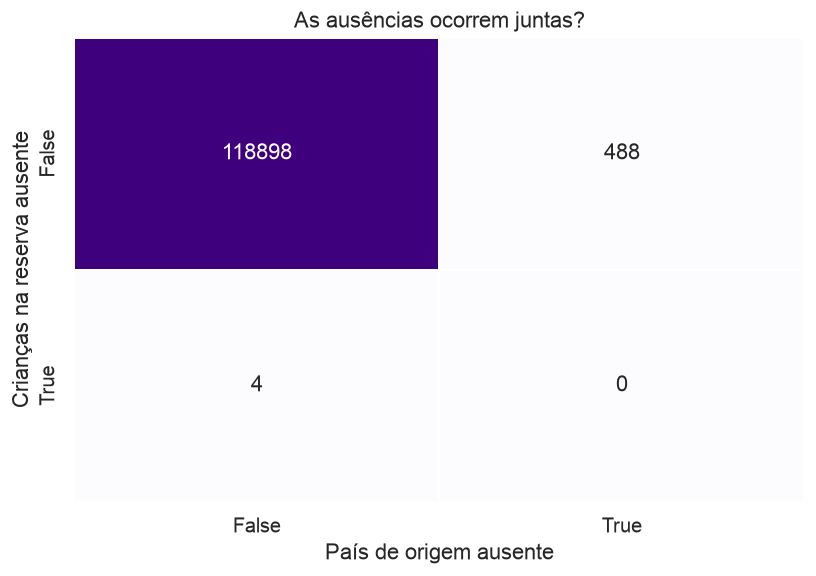

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{ROTULOS.get(cols_com_ausentes[0], cols_com_ausentes[0])} ausente"],
            colnames=[f"{ROTULOS.get(cols_com_ausentes[1], cols_com_ausentes[1])} ausente"])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="Purples", linewidths=1,
            linecolor="white", cbar=False, annot_kws={"fontsize": 13}, ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

**✍️ Resposta (análise individual)**

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, hóspedes de um determinado país preferem não declarar a nacionalidade, justamente por causa do país que é — a ausência carregaria informação sobre o valor que falta, e isso seria **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, um turno específico da recepção que não preenchia esse campo, ou um canal de venda que nem pedia a nacionalidade no formulário — nesse caso a ausência depende do contexto da coleta, não do valor, e cai em **MAR** (ou até **MCAR**, se for simplesmente esquecimento espalhado sem padrão nenhum).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem opera o sistema do hotel) resolveriam a dúvida. Na ausência disso, eu sigo com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["lead_time", "total_of_special_requests", "adr", "stays_in_week_nights", "previous_cancellations"]
VARS_QUALI = ["hotel", "market_segment", "meal", "distribution_channel", "is_repeated_guest", "customer_type", "children", "deposit_type"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .rename(index=ROTULOS)
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Antecedência da reserva (dias),104.01,69.00,106.86,0.00,737.00,1.35,1.70
Pedidos especiais,0.57,0.00,0.79,0.00,5.00,1.35,1.49
Diária média (€),101.83,94.58,50.54,-6.38,5400.00,10.53,1013.19
Noites em dias de semana,2.50,2.00,1.91,0.00,50.00,2.86,24.28
Cancelamentos anteriores,0.09,0.00,0.84,0.00,26.00,24.46,674.07


> ❓ **Para discutir**
>
> olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?
>
> Isso é coerente com o que vocês esperariam do negócio (ex: a maioria das reservas tem diária dentro de uma faixa comum e umas pouquíssimas explodem em valor; quase todo hóspede tem zero cancelamentos anteriores e uns raros reincidentes têm vários)?

**✍️ Resposta (análise individual)**

Todas as cinco variáveis têm `skewness` acima de 1, então **nenhuma** é simétrica. Os casos extremos são a diária média e os cancelamentos anteriores: `adr` tem skew ≈ 10,5 e curtose ≈ 1013 (uma única reserva de 5.400 estica a cauda inteira), e `previous_cancellations` tem skew ≈ 24 e curtose ≈ 674 (quase todo mundo tem zero, uns pouquíssimos reincidentes puxam a cauda pra longe). `lead_time` (1,35), pedidos especiais (1,35) e noites de semana (2,86) são assimétricas à direita, mas bem mais comportadas.

Isso bate exatamente com o que eu esperaria do negócio: a maioria das reservas fica numa faixa de diária comum e pouquíssimas explodem em valor; e quase todo hóspede tem zero cancelamentos anteriores, com raros reincidentes. Ou seja, a assimetria aqui não é ruído, é o retrato fiel de como reservas de hotel se comportam. Na prática isso já me avisa duas coisas: pra descrever/imputar essas variáveis a **mediana** é mais confiável que a média, e testes que exigem normalidade provavelmente vão falhar — confirmo isso no Shapiro-Wilk logo abaixo.


### Distribuições de dados

Onde fizer sentido, comparo "Mantida" (azul) vs. "Cancelada" (laranja). Escolhi esse par de cores de propósito: azul e laranja continuam distinguíveis para pessoas com daltonismo (diferente do clássico vermelho/verde), e mantenho essa convenção até a análise bivariada.

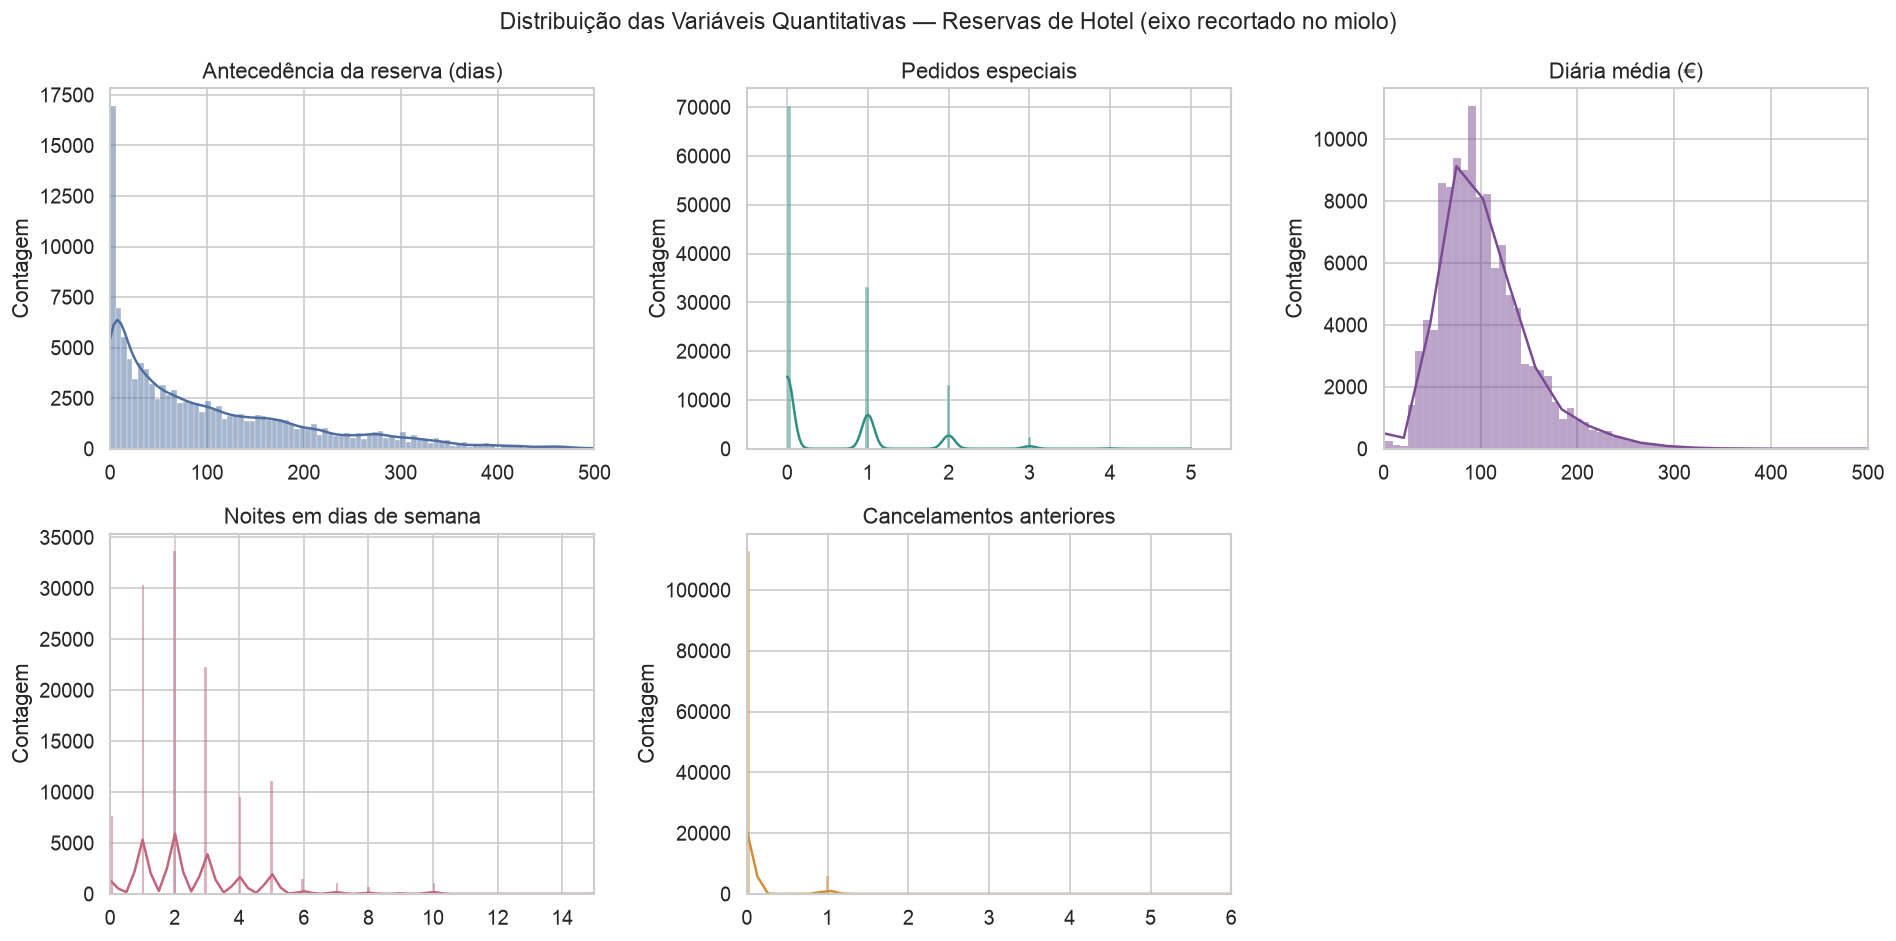

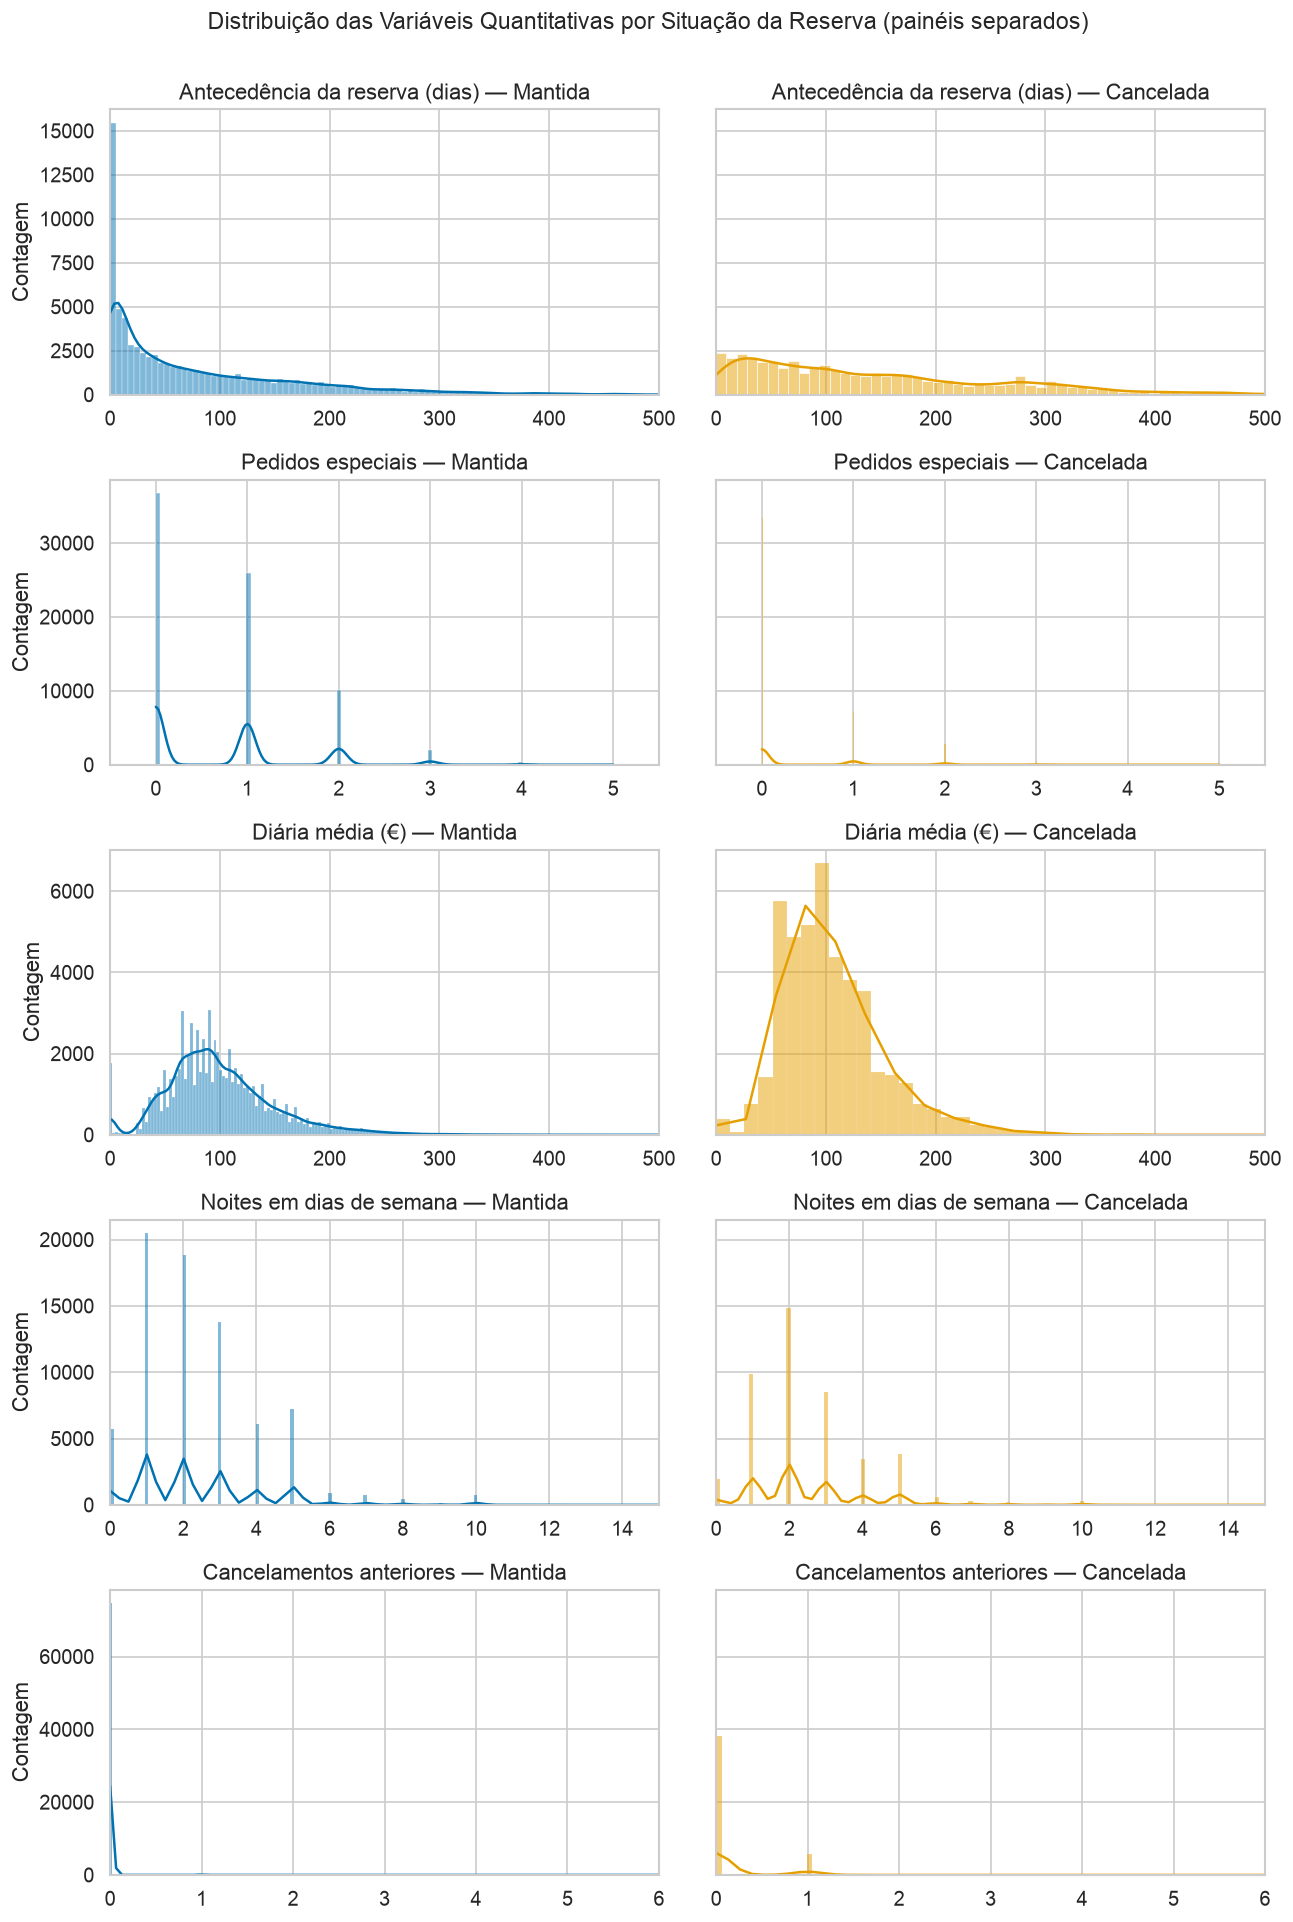

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=PALETA_VARS[col], edgecolor="white", ax=axes[i])
    axes[i].set_xlim(LIMITES_EXIBICAO[col])
    axes[i].set_title(ROTULOS[col])
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Contagem")

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas — Reservas de Hotel (eixo recortado no miolo)", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(11, 3.2 * len(VARS_QUANT)), sharey="row")

for i, col in enumerate(VARS_QUANT):
    lim = LIMITES_EXIBICAO[col]
    for j, (classe, cor) in enumerate([("Mantida", COR_CONTEXTO), ("Cancelada", COR_DESTAQUE)]):
        subset = df[df["cancelamento"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, edgecolor="white", ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{ROTULOS[col]} — {classe}")
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylabel("Contagem" if j == 0 else "")

fig.suptitle("Distribuição das Variáveis Quantitativas por Situação da Reserva (painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()


> ❓ **Para discutir**
>
> agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Mantida" e "Cancelada"?

**✍️ Resposta (análise individual)**

A variável que mais muda de formato entre as classes é a **antecedência** (`lead_time`): nas reservas mantidas a massa se concentra perto de zero (mediana de 45 dias), enquanto nas canceladas a distribuição é bem mais espalhada e deslocada pra direita (mediana de 113 dias). Traduzindo: quem reserva com muita antecedência cancela mais.

**Pedidos especiais** também separa bem, só que ao contrário — reservas mantidas costumam ter pelo menos 1 pedido, e as canceladas se concentram em 0 (faz sentido: quem já pediu berço ou andar alto está mais comprometido com a viagem). Já `adr`, noites de semana e cancelamentos anteriores têm formato praticamente igual nas duas classes. Esse olhar já me antecipa quem são os melhores candidatos a diferenciar cancelamento na análise bivariada: `lead_time` e pedidos especiais.


#### Testes de Aderência

*Será se a diária média segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `adr`.

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["adr"].dropna())
print(f"Shapiro-Wilk — adr: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

Shapiro-Wilk — adr: estatística=0.8672, p-valor=3.307e-124
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


/Users/miguelandrade/Projects/aula11-eda/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 119390.
  res = hypotest_fun_out(*samples, **kwds)


### QQ-Plot — diária média (adr)

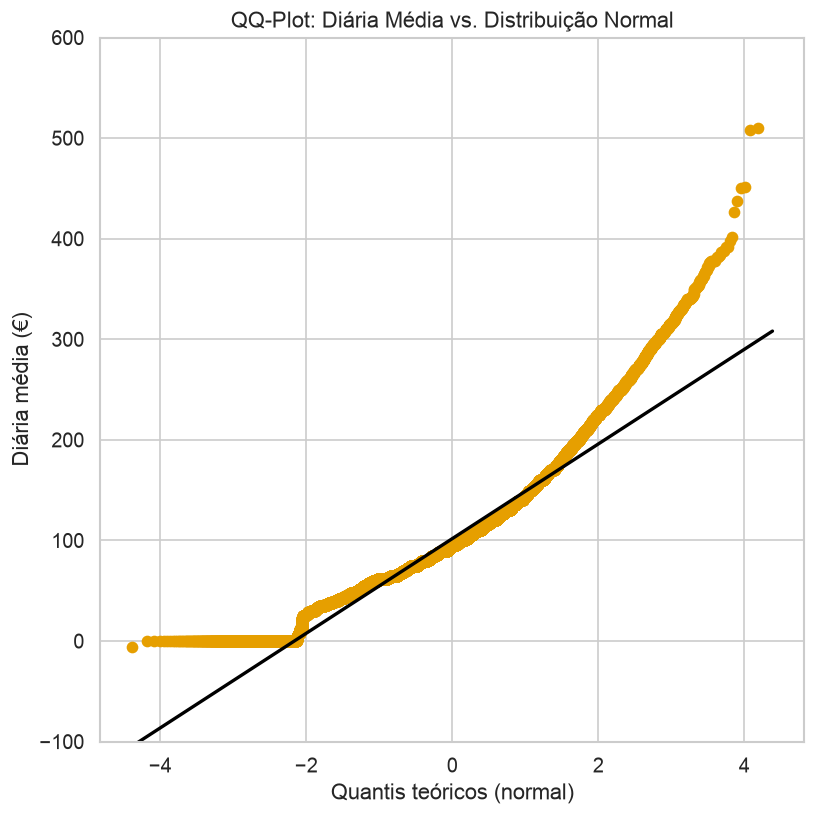

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
stats.probplot(df["adr"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_DESTAQUE)
ax.get_lines()[0].set_markeredgecolor(COR_DESTAQUE)
ax.get_lines()[1].set_color("black")
ax.get_lines()[1].set_linewidth(2)
ax.set_title("QQ-Plot: Diária Média vs. Distribuição Normal")
ax.set_xlabel("Quantis teóricos (normal)")
ax.set_ylabel(ROTULOS["adr"])
ax.set_ylim(-100, 600)
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (laranja) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** deixam o teste sensível demais, rejeitando por desvios triviais — e é justamente o caso aqui: com mais de 119 mil linhas, o Shapiro-Wilk vai rejeitar praticamente qualquer variável, e o próprio SciPy avisa que o p-valor deixa de ser confiável acima de ~5.000 observações. Ou seja: o p-valor sozinho não decide nada nesta base. Quem sustenta a conclusão são as outras evidências (skewness de 10,5 e um QQ-Plot que abandona a reta na cauda direita), não o teste.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel").rename(index=ROTULOS)

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Antecedência da reserva (dias),0.8568,0.0,True
Pedidos especiais,0.7166,0.0,True
Diária média (€),0.8672,0.0,True
Noites em dias de semana,0.8022,0.0,True
Cancelamentos anteriores,0.0660,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`adr`, a diária média da reserva), só pra fixar como essa visualização se lê.

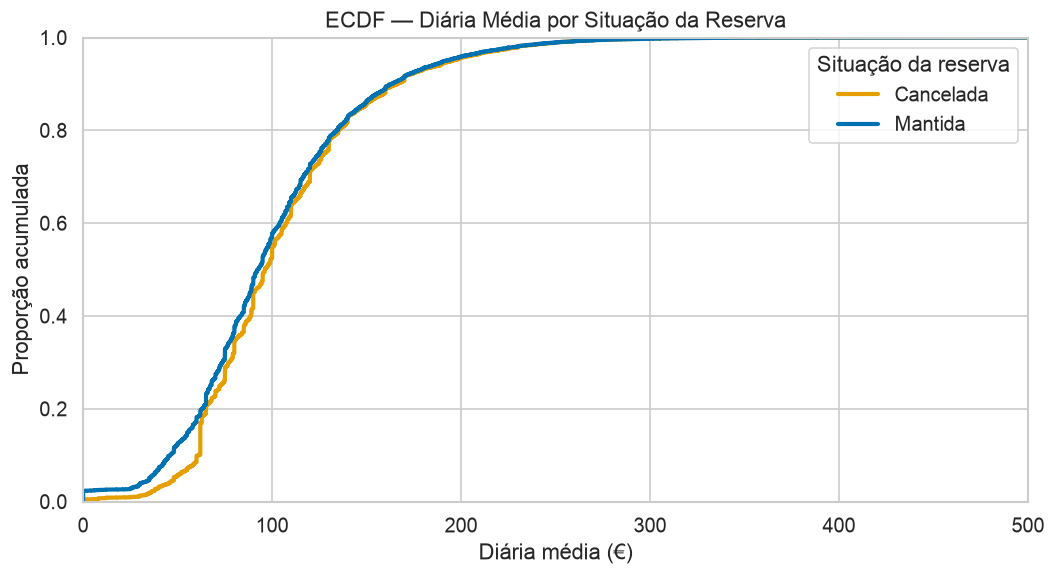

In [ ]:
plt.figure(figsize=(9, 5))
sns.ecdfplot(data=df, x="adr", hue="cancelamento", linewidth=2.5,
             palette={"Mantida": COR_CONTEXTO, "Cancelada": COR_DESTAQUE})
plt.title("ECDF — Diária Média por Situação da Reserva")
plt.xlabel(ROTULOS["adr"])
plt.ylabel("Proporção acumulada")
plt.xlim(0, 500)
plt.legend(title="Situação da reserva", labels=["Cancelada", "Mantida"])
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das reservas desse grupo tem diária até aqui". Onde as duas curvas (azul e laranja) se distanciam mais, ali está a faixa de preço em que reservas mantidas e canceladas mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

In [ ]:
media_adr = df["adr"].mean()
mediana_adr = df["adr"].median()

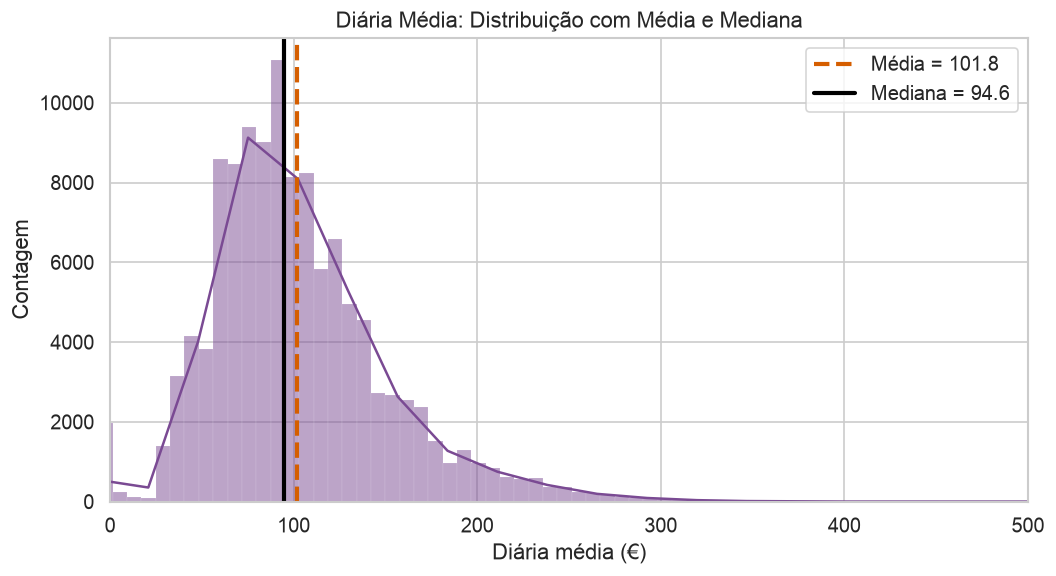

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="adr", kde=True, color=PALETA_VARS["adr"], edgecolor="white")
plt.axvline(media_adr, color=COR_ALERTA, linestyle="--", linewidth=2.5, label=f"Média = {media_adr:.1f}")
plt.axvline(mediana_adr, color="black", linestyle="-", linewidth=2.5, label=f"Mediana = {mediana_adr:.1f}")
plt.title("Diária Média: Distribuição com Média e Mediana")
plt.xlabel(ROTULOS["adr"])
plt.ylabel("Contagem")
plt.xlim(0, 500)
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.rename(index=ROTULOS).round(2)

,var,std,IQR
Antecedência da reserva (dias),11419.72,106.86,142.00
Pedidos especiais,0.63,0.79,1.00
Diária média (€),2553.87,50.54,56.71
Noites em dias de semana,3.64,1.91,2.00
Cancelamentos anteriores,0.71,0.84,0.00


### Boxplot e violin plot por classe

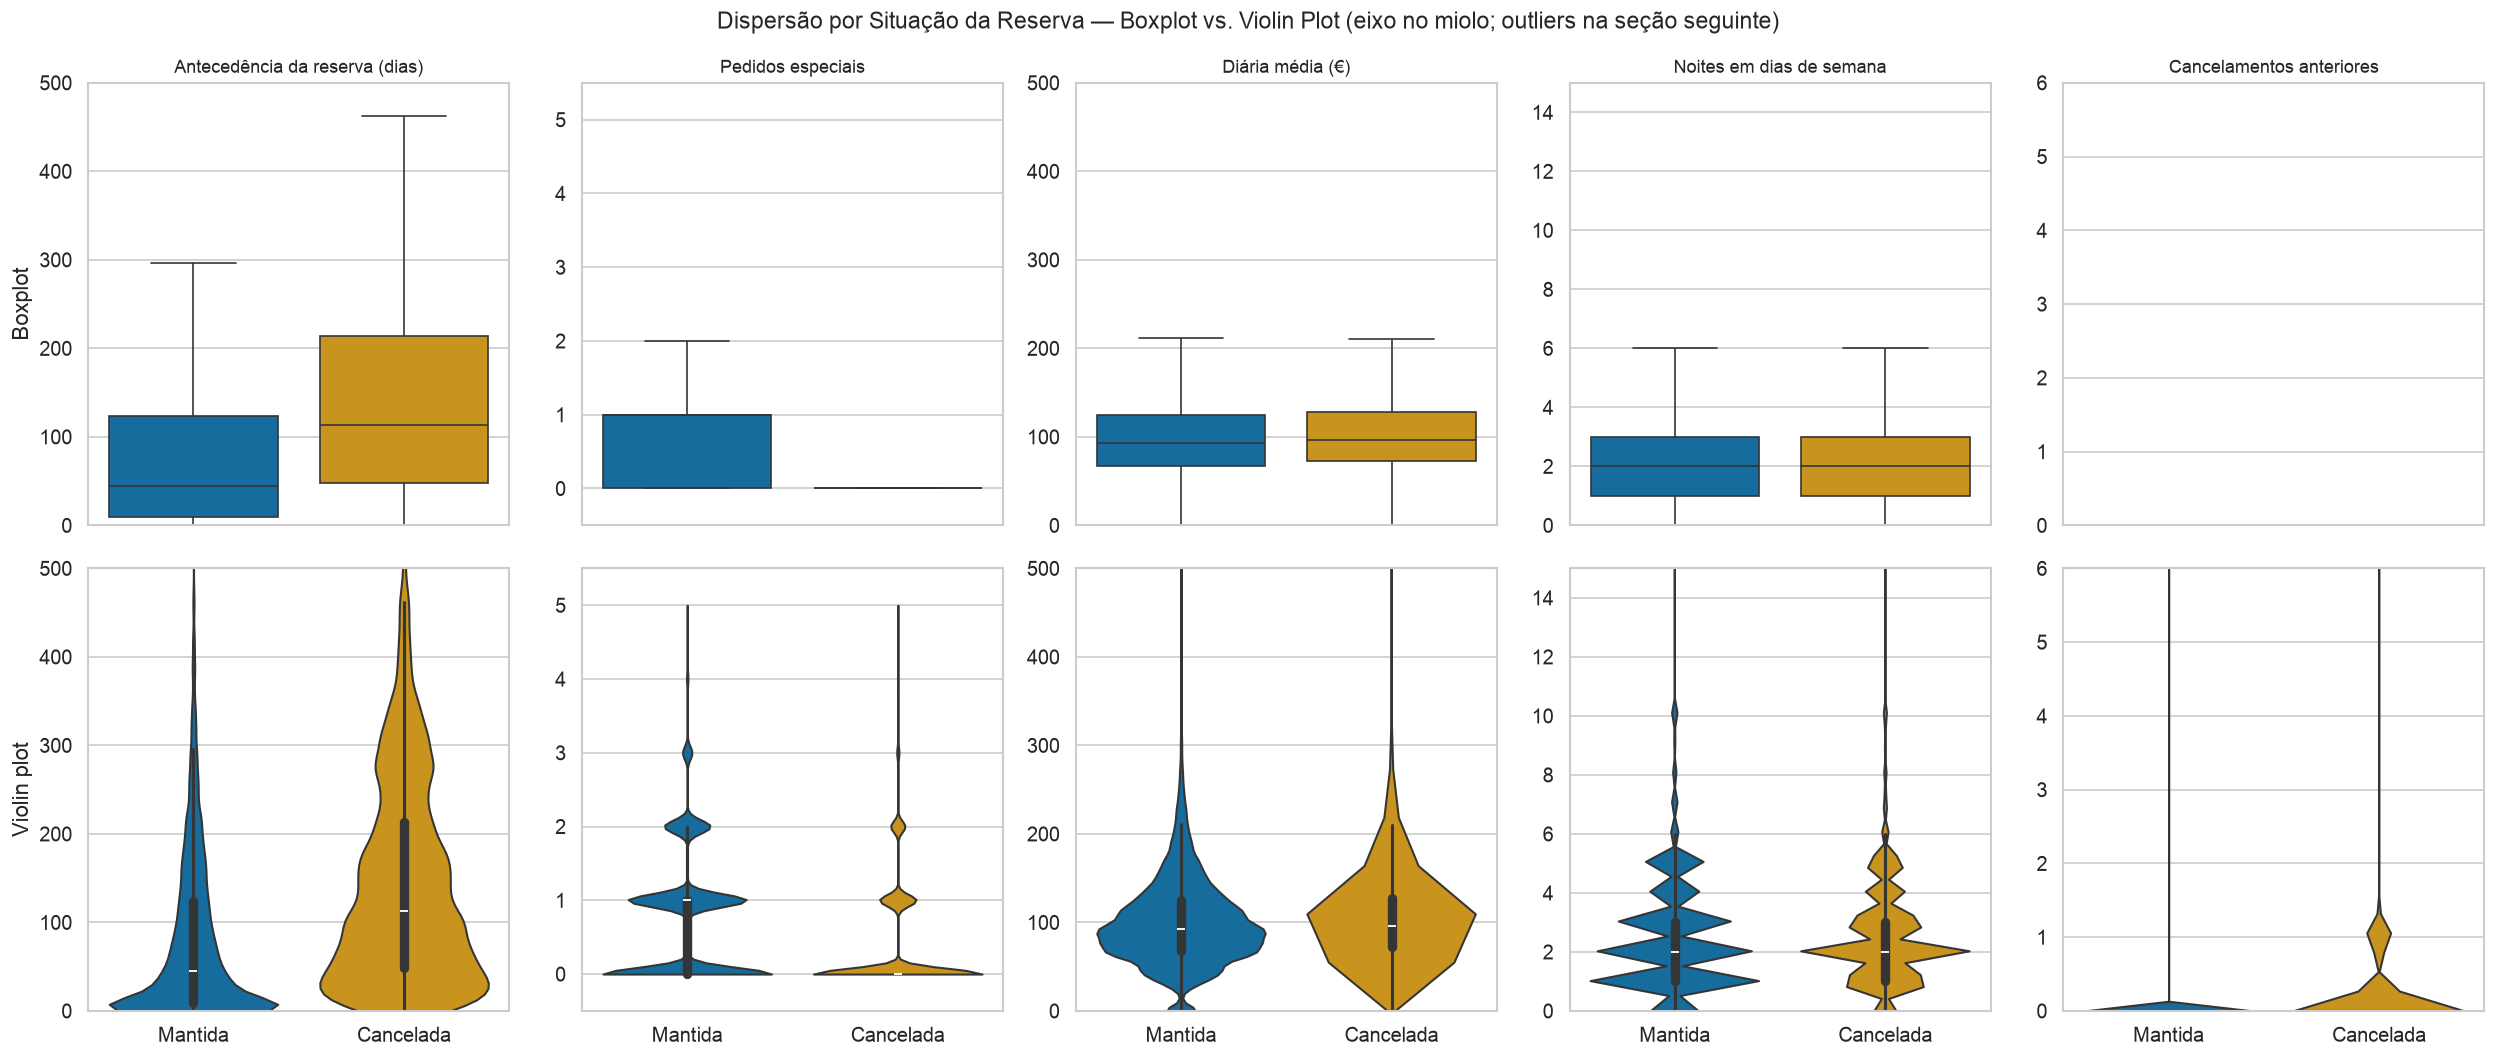

In [ ]:
palette_classe = {"Mantida": COR_CONTEXTO, "Cancelada": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4.2 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="cancelamento", y=col, hue="cancelamento", showfliers=False,
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(ROTULOS[col], fontsize=11)
    axes[0, i].set_xlabel("")
    axes[0, i].set_ylim(LIMITES_EXIBICAO[col])

    sns.violinplot(data=df, x="cancelamento", y=col, hue="cancelamento", cut=0,
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")
    axes[1, i].set_ylim(LIMITES_EXIBICAO[col])

for i in range(len(VARS_QUANT)):
    axes[0, i].set_ylabel("")
    axes[1, i].set_ylabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Situação da Reserva — Boxplot vs. Violin Plot (eixo no miolo; outliers na seção seguinte)", fontsize=14)
plt.tight_layout()
plt.show()


> ❓ **Para discutir**
>
> alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Mantida" e "Cancelada"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

**✍️ Resposta (análise individual)**

Sim, e de novo é a **antecedência** que salta aos olhos: a caixa (IQR) das reservas canceladas está claramente acima da caixa das mantidas — mediana em torno de 113 dias contra 45. Pra mim é o indício mais forte, antes mesmo de qualquer teste, de que `lead_time` ajuda a separar as classes. Em **pedidos especiais** acontece o inverso em miniatura: a mediana das mantidas é 1 e a das canceladas é 0.

Nas outras três variáveis (`adr`, noites de semana e cancelamentos anteriores) as caixas praticamente se sobrepõem, então não espero que elas ajudem muito a distinguir cancelamento. Guardo essa leitura pra conferir depois com o Mann-Whitney: se o teste concordar que a diferença em `lead_time` é real, fecho a hipótese.


## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`children`, `country`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T.rename(index=ROTULOS)

,limite_inferior,limite_superior,n_outliers
Antecedência da reserva (dias),-195.00,373.00,3005.0
Pedidos especiais,-1.50,2.50,2877.0
Diária média (€),-15.77,211.06,3793.0
Noites em dias de semana,-2.00,6.00,3354.0
Cancelamentos anteriores,0.00,0.00,6484.0


### Visualizando os Outliers

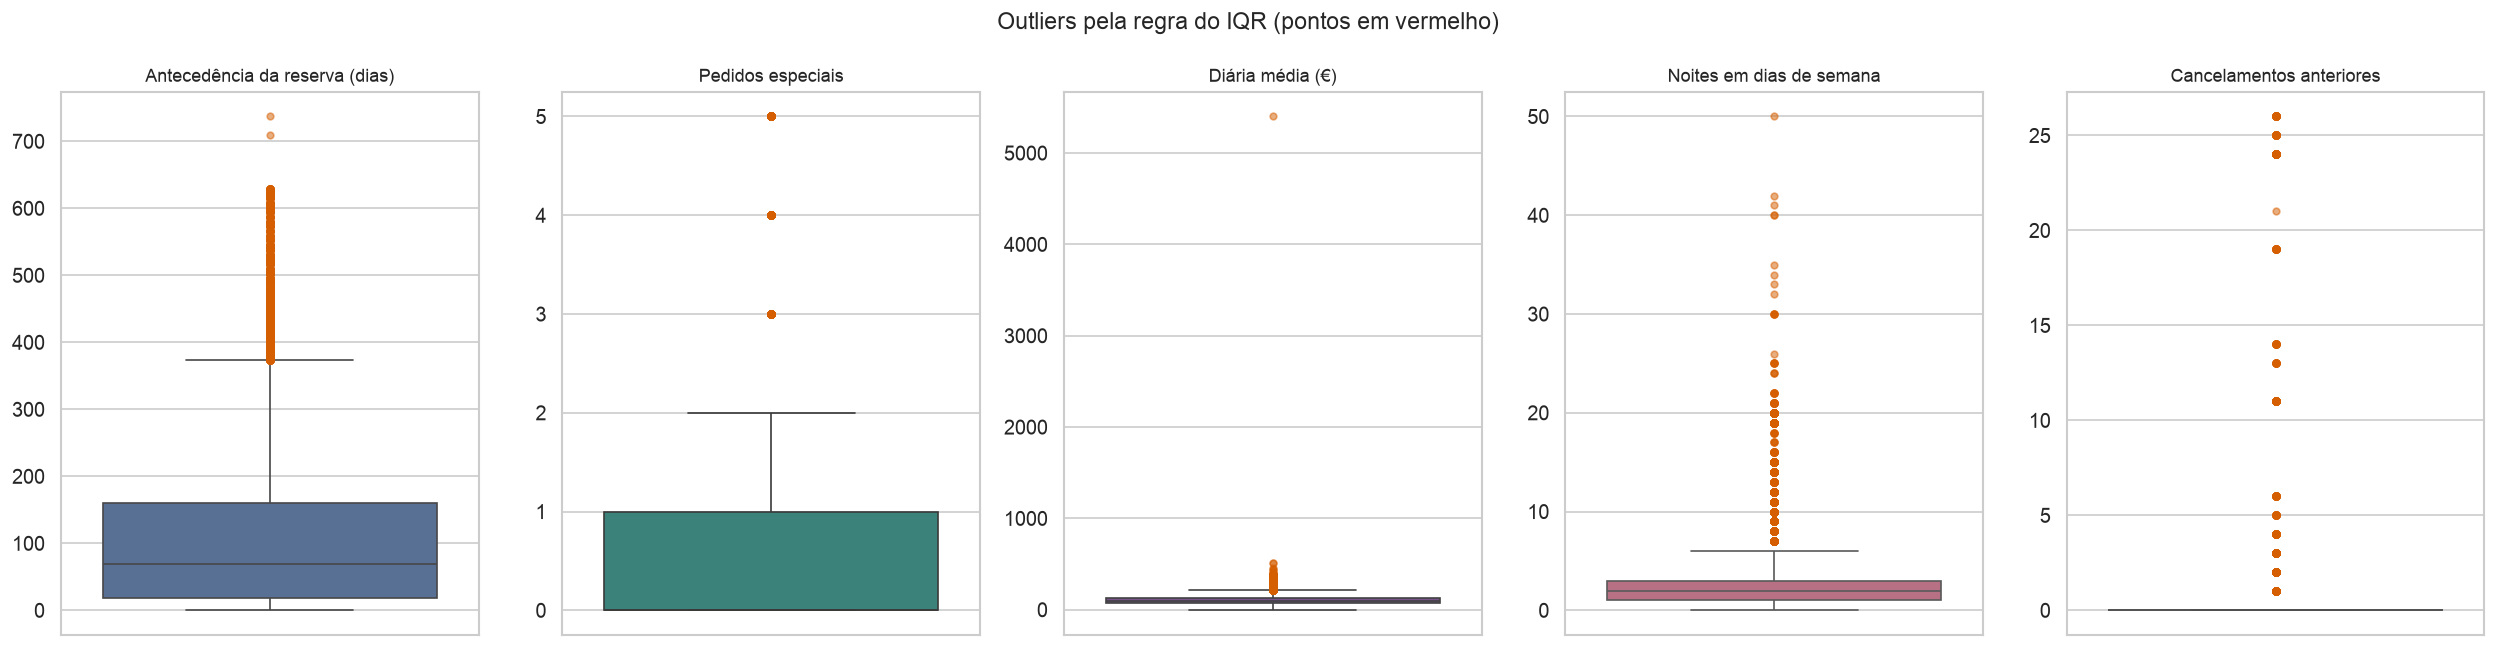

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4.2 * len(VARS_QUANT), 5.5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=PALETA_VARS[col],
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA,
                                marker="o", markersize=4, alpha=0.5),
                ax=axes[i])
    axes[i].set_title(ROTULOS[col], fontsize=11)
    axes[i].set_ylabel("")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:
>
> | Tipo | Cenário | O que fazer? |
> |---|---|---|
> | Estatístico | Legítimo | Manter / Transformar |
> | De domínio | Viola regra de negócio ou condições físicas | Investigar! |
> | Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

**✍️ Resposta (análise individual)**

Olhando os outliers de `adr`, dá pra ver os três tipos convivendo na mesma coluna: a maioria dos valores altos é apenas **estatística** (suíte em alta temporada custa caro, e isso é real); tem uma reserva com diária **negativa**, que viola a regra de negócio mais óbvia possível (preço não pode ser menor que zero) e é claramente **erro de dados**; e tem uma única reserva de 5.400, uns 50x acima da mediana, que é o caso clássico de **investigar** antes de decidir — pode ser um pacote de evento legítimo ou uma vírgula no lugar errado.

Repare também no que aconteceu com `previous_cancellations`: como mais de 75% das reservas têm valor zero, Q1 e Q3 são ambos zero, o IQR vira zero e a regra passa a marcar **qualquer** valor diferente de zero como outlier. Isso não é um defeito dos dados, é um limite da própria regra do IQR em variáveis muito concentradas em um único valor.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: para `children` e `country` o mecanismo mais provável é MAR ou MCAR (não MNAR), e o volume é pequeno (492 linhas em 119.390, menos de 0,5%). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo e o custo de perder meio por cento da base é praticamente nulo. A coluna `company` eu **já removi lá na Seção 2** (94% de vazios, sem valor analítico). Sobra `agent`, que fica **de fora** desse descarte de propósito: ali o vazio quer dizer "reserva direta, sem agência", e remover essas linhas jogaria fora boa parte da base por um problema que não existe.

Aproveito o mesmo passo para corrigir o único **erro de dados** que identifiquei lá na visualização de outliers: a reserva com diária **negativa**. Preço abaixo de zero é impossível, não dá pra recuperar o valor real de uma linha só, e a recomendação para "erro de dados" é justamente corrigir ou, em último caso, remover. Como é uma única linha, removê-la é a saída mais simples e sem efeito colateral relevante — e de quebra o `log1p` que uso logo abaixo passa a rodar sem `NaN`.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# Erro de dados: diária negativa é impossível (preço não pode ser < 0). Corrijo removendo a única linha.
df = df[df["adr"] >= 0]

# Ausência de preenchimento: children e country (< 0,5% da base). Removo as linhas.
df = df.dropna(subset=["children", "country"]).reset_index(drop=True)

linhas_depois = df.shape[0]


In [ ]:
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 119390 | Linhas depois: 118897 | Removidas: 493


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. A grande maioria dos valores extremos que encontramos é do tipo **"Estatístico"**: diárias altas em alta temporada, estadias longas, hóspedes com histórico de cancelamento. São dados reais e, mais do que isso, provavelmente são exatamente as reservas mais interessantes do ponto de vista de negócio — quem paga mais caro e reserva com muita antecedência tende a ter um comportamento de cancelamento diferente. Jogar isso fora seria apagar justamente o sinal que queremos estudar.

Vou manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `adr` — útil caso, mais adiante, a assimetria atrapalhe algum teste ou modelo. Como já corrigi a diária negativa no passo anterior, o `log1p` roda limpo (sem `NaN`); o único detalhe que sobra são as reservas com diária igual a zero (cortesias, promoções), que caem todas em `log(1) = 0` e criam um pico à esquerda — comento isso na discussão logo abaixo.

In [ ]:
df["adr_log"] = np.log1p(df["adr"])

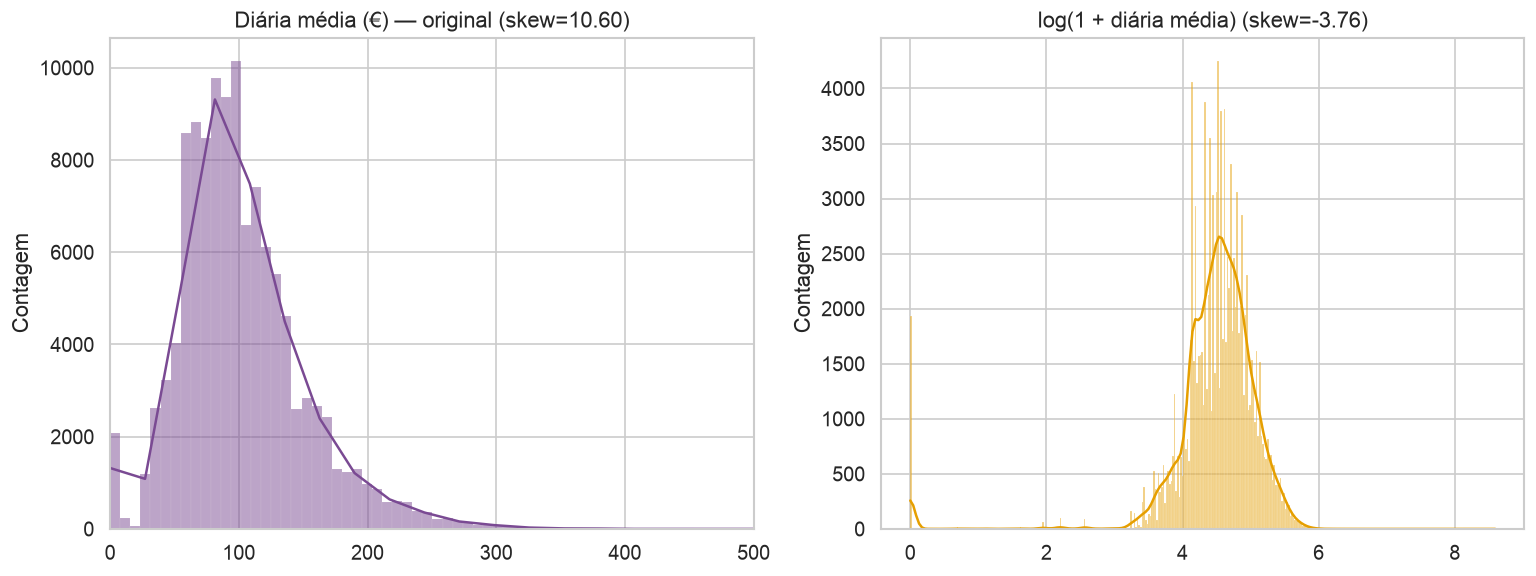

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df, x="adr", kde=True, color=PALETA_VARS["adr"], edgecolor="white", ax=axes[0])
axes[0].set_title(f"{ROTULOS['adr']} — original (skew={df['adr'].skew():.2f})")
axes[0].set_xlabel("")
axes[0].set_xlim(0, 500)
axes[0].set_ylabel("Contagem")
axes[1].set_ylabel("Contagem")

sns.histplot(data=df, x="adr_log", kde=True, color=COR_DESTAQUE, edgecolor="white", ax=axes[1])
axes[1].set_title(f"{ROTULOS['adr_log']} (skew={df['adr_log'].skew():.2f})")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `adr_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**✍️ Resposta (análise individual)**

Reduziu, mas com uma ressalva que vale registrar: o `skewness` de `adr` saiu de ≈ 10,5 pra ≈ -3,7. **Em módulo** caiu bastante — a cauda direita gigante, puxada pela diária de 5.400, foi comprimida — só que o sinal virou **negativo**. O culpado é a montanha de reservas com diária igual a zero (cortesias, promoções): como `log1p(0) = 0`, elas viram um pico à esquerda que agora domina a assimetria. Depois que corrigi a diária negativa lá no tratamento, o `log1p` não gera mais `NaN`, então o que sobra é só esse efeito das diárias zero.

Ou seja: o log resolve o problema da cauda direita, mas não entrega uma normal — pra um teste paramétrico eu ainda teria que lidar com o excesso de zeros. Por isso mantenho `adr_log` só como demonstração e sigo usando testes **não-paramétricos**, que não dependem de normalidade.


**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .rename(index=ROTULOS)
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Antecedência da reserva (dias),104.31,69.00,106.90,0.00,737.00,1.34,1.69
Pedidos especiais,0.57,0.00,0.79,0.00,5.00,1.35,1.48
Diária média (€),102.00,95.00,50.49,0.00,5400.00,10.60,1021.35
Noites em dias de semana,2.50,2.00,1.90,0.00,41.00,2.70,19.98
Cancelamentos anteriores,0.09,0.00,0.85,0.00,26.00,24.43,671.95


### Comparando "antes"x "depois""

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.rename(index=ROTULOS).round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Antecedência da reserva (dias),1.347,1.344,1.696,1.691,-0.002,-0.006
Pedidos especiais,1.349,1.347,1.493,1.480,-0.002,-0.013
Diária média (€),10.530,10.600,1013.190,1021.346,0.070,8.156
Noites em dias de semana,2.862,2.698,24.285,19.984,-0.164,-4.301
Cancelamentos anteriores,24.458,24.425,674.074,671.952,-0.033,-2.121


> ❓ **Para discutir**
>
> os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos menos de 0,5% das linhas e decidimos **não** alterar nenhum outlier?

**✍️ Resposta (análise individual)**

Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**A diária média ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["adr"].dropna())
print(f"Shapiro-Wilk (antes)  — adr: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — adr: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — adr: estatística=0.8672, p-valor=3.307e-124
Shapiro-Wilk (depois) — adr: estatística=0.8664, p-valor=2.723e-124


/Users/miguelandrade/Projects/aula11-eda/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 118897.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`adr` e `previous_cancellations`), comparando a versão original (`df_antes`) com a tratada (`df`).

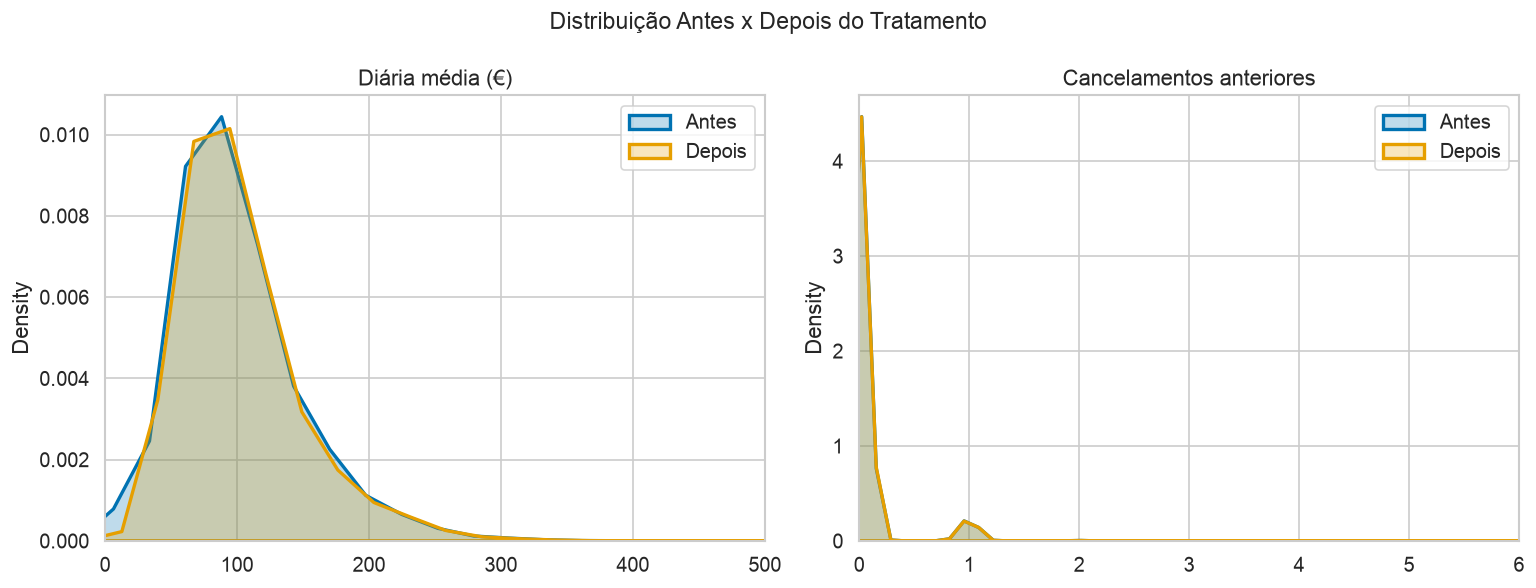

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, ["adr", "previous_cancellations"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, linewidth=2, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, linewidth=2, label="Depois", ax=ax)
    ax.set_title(ROTULOS[col])
    ax.set_xlabel("")
    ax.set_xlim(LIMITES_EXIBICAO[col])
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

**✍️ Resposta (análise individual)**

Guardo essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {ROTULOS[col]} ({col}) ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- Unidade do hotel (hotel) ---
              absoluta  relativa
hotel                           
City Hotel       79302     0.667
Resort Hotel     39595     0.333

--- Segmento de mercado (market_segment) ---
                absoluta  relativa
market_segment                    
Online TA          56402     0.474
Offline TA/TO      24160     0.203
Groups             19805     0.167
Direct             12448     0.105
Corporate           5111     0.043
Complementary        734     0.006
Aviation             237     0.002

--- Regime de refeição (meal) ---
           absoluta  relativa
meal                         
BB            91862     0.773
HB            14434     0.121
SC            10638     0.089
Undefined      1165     0.010
FB              798     0.007

--- Canal de distribuição (distribution_channel) ---
                      absoluta  relativa
distribution_channel                    
TA/TO                    97730     0.822
Direct                   14482     0.122
Corporate 

#### Visualizando as frequências

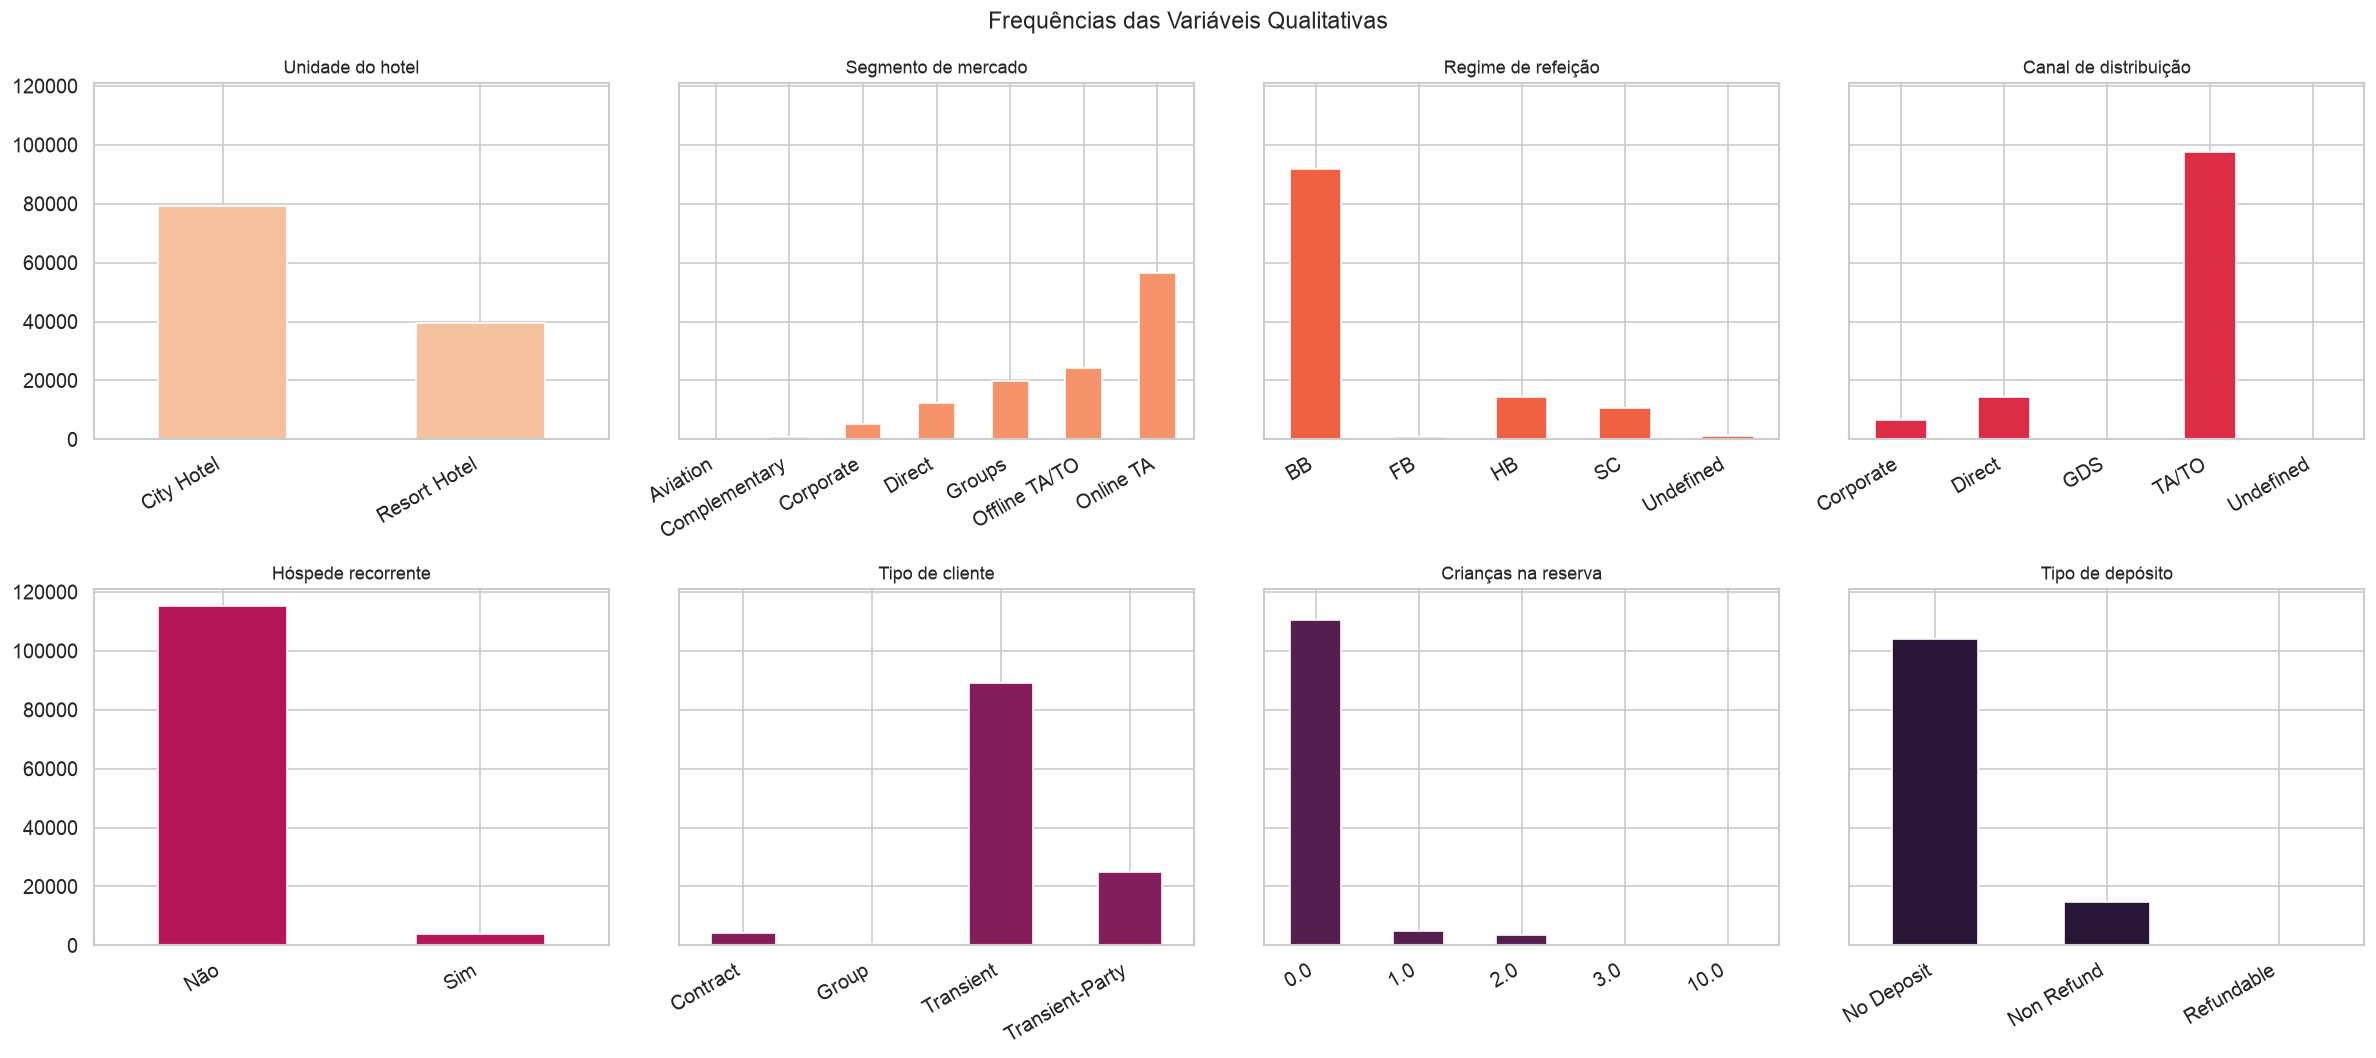

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    serie_exibicao = df[col].replace(VALORES_EXIBICAO.get(col, {}))
    serie_exibicao.value_counts().sort_index().plot(kind="bar", color=PALETA_QUALI[i],
                                                   edgecolor="white", ax=axes[i])
    axes[i].set_title(ROTULOS[col], fontsize=11)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)
    for rotulo in axes[i].get_xticklabels():
        rotulo.set_ha("right")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)?

**✍️ Resposta (análise individual)**

Olhando `distribution_channel` e `deposit_type`, por exemplo: a maior parte das reservas se concentra em uma única categoria, o que significa que as categorias raras vão aparecer com pouquíssimas linhas nos cruzamentos da análise bivariada — e conclusão tirada de 200 reservas não tem o mesmo peso de conclusão tirada de 100 mil.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `cancelamento`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["cancelamento"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T.rename(index=ROTULOS)

,n_classes,razao_desbalanceamento,entropia_normalizada
Unidade do hotel,2.0,2.00,0.918
Segmento de mercado,7.0,237.98,0.715
Regime de refeição,5.0,115.12,0.466
Canal de distribuição,5.0,97730.00,0.365
Hóspede recorrente,2.0,30.25,0.204
Tipo de cliente,4.0,156.45,0.494
Crianças na reserva,5.0,110318.00,0.194
Tipo de depósito,3.0,642.98,0.348
Situação da reserva,2.0,1.69,0.952


> ❓ **Para discutir**
>
> alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `cancelamento` — com cerca de 37% de reservas canceladas, ele está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

**✍️ Resposta (análise individual)**

(Spoiler: 37/63 é um desbalanceamento leve, bem mais confortável do que os cenários de 1% de classe positiva que aparecem em fraude ou churn.)

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'cancelamento'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

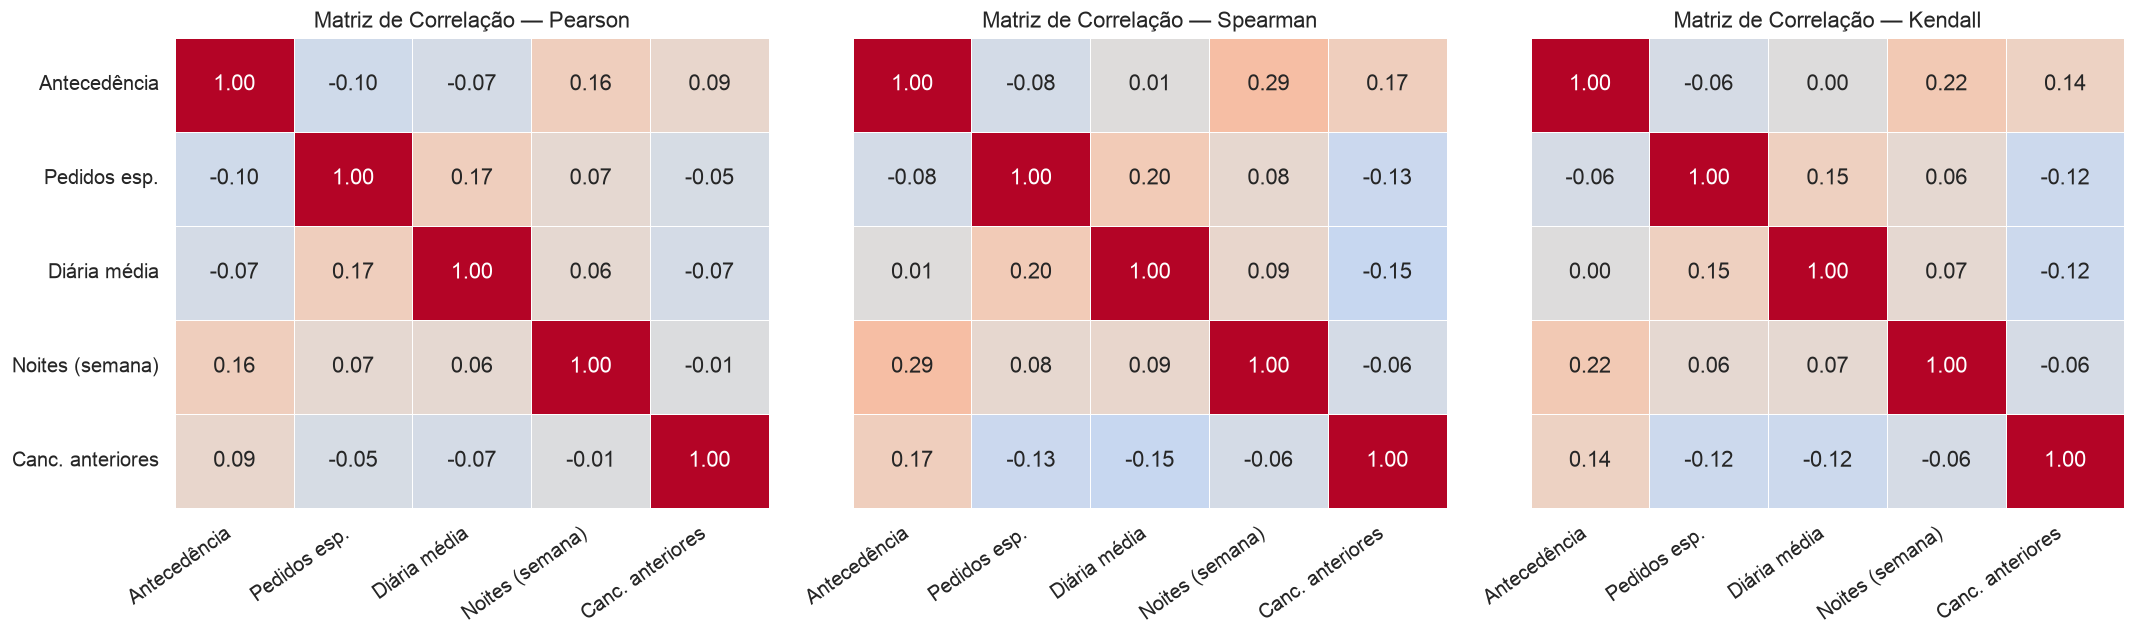

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
sns.heatmap(corr_pearson.rename(index=ROTULOS_CURTOS, columns=ROTULOS_CURTOS), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, linecolor="white", cbar=False, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman.rename(index=ROTULOS_CURTOS, columns=ROTULOS_CURTOS), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, linecolor="white", cbar=False, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall.rename(index=ROTULOS_CURTOS, columns=ROTULOS_CURTOS), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, linecolor="white", cbar=False, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")

for eixo in ax:
    eixo.tick_params(axis="x", rotation=35)
    for rotulo in eixo.get_xticklabels():
        rotulo.set_ha("right")

plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

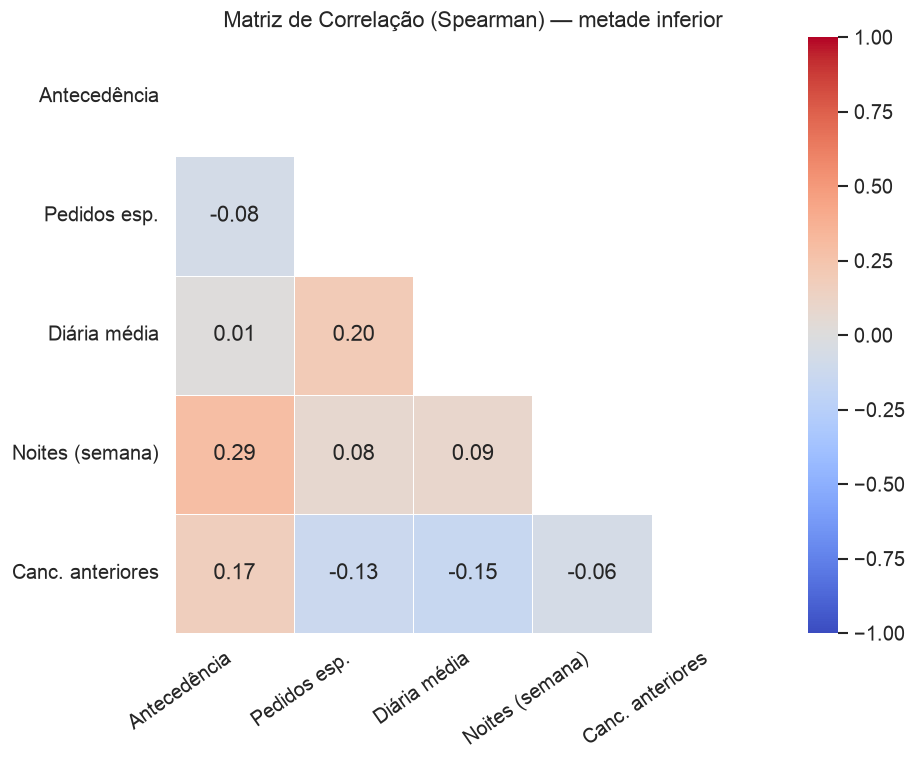

In [ ]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_spearman.rename(index=ROTULOS_CURTOS, columns=ROTULOS_CURTOS), mask=mask, annot=True,
            cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1, linewidths=0.5, linecolor="white")
plt.title("Matriz de Correlação (Spearman) — metade inferior")
plt.grid(False)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> Pearson e Spearman divergem bastante em algum par de variáveis?

**✍️ Resposta (análise individual)**

Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não. Preste atenção especial nos pares que envolvem `adr` — aquela diária de 5.400 tem força pra distorcer o Pearson sozinha, enquanto o Spearman, por trabalhar com postos, quase não sente.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `lead_time` x `stays_in_week_nights` por um motivo de domínio, não só estatístico: quem reserva com muita antecedência costuma estar planejando uma estadia mais longa (férias, viagem programada), enquanto reserva de última hora tende a ser uma ou duas noites. É uma hipótese de negócio que dá pra checar no gráfico.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

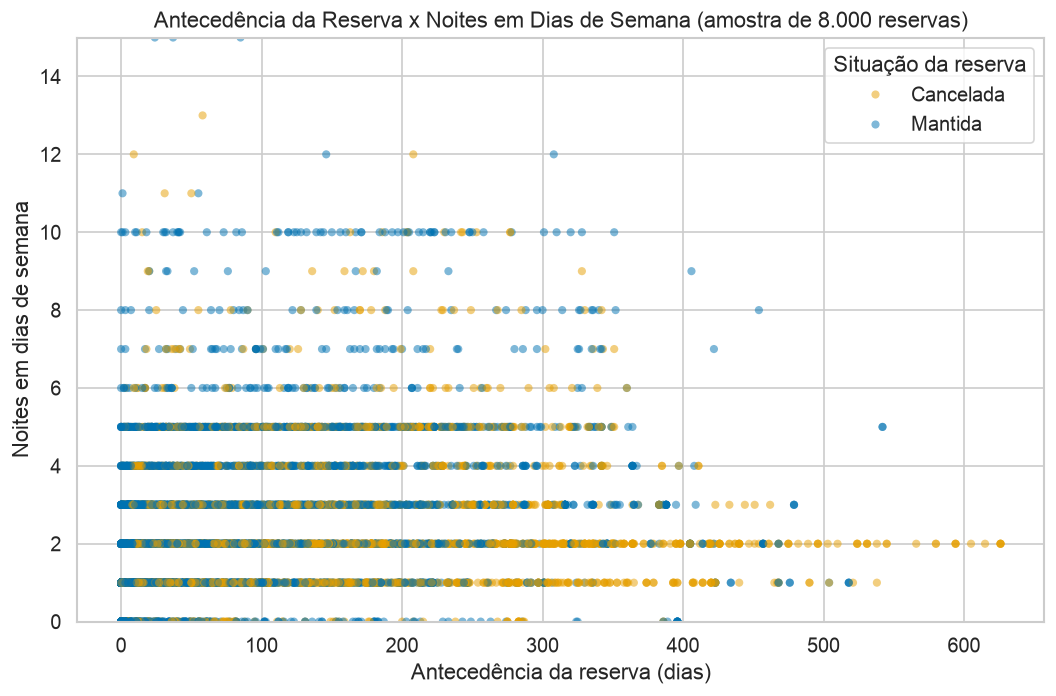

In [ ]:
amostra = df.sample(n=8000, random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=amostra, x="lead_time", y="stays_in_week_nights", hue="cancelamento",
                palette={"Mantida": COR_CONTEXTO, "Cancelada": COR_DESTAQUE},
                alpha=0.5, s=24, edgecolor="none")
plt.ylim(0, 15)
plt.title("Antecedência da Reserva x Noites em Dias de Semana (amostra de 8.000 reservas)")
plt.xlabel(ROTULOS["lead_time"])
plt.ylabel(ROTULOS["stays_in_week_nights"])
plt.legend(title="Situação da reserva")
plt.tight_layout()
plt.show()


> ❓ **Para discutir**
>
> existe uma tendência visível (conforme a antecedência aumenta, `stays_in_week_nights` tende a subir)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

**✍️ Resposta (análise individual)**

Como a base tem mais de 100 mil reservas, o scatter cru satura — os pontos empilham uns sobre os outros e a mancha escura esconde a densidade real. Por isso plotei uma **amostra aleatória de 8.000 reservas** com transparência (`alpha`) e recortei o eixo Y no miolo: assim dá pra ver que a nuvem de reservas canceladas (laranja) se espalha mais para antecedências altas, enquanto as mantidas (azul) se concentram perto de zero. Em bases desse tamanho, amostra + `alpha` (ou um hexbin) conta a história bem melhor do que o scatter completo.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_mantida = df.loc[df["cancelamento"] == "Mantida", col]
    grupo_cancelada = df.loc[df["cancelamento"] == "Cancelada", col]

    stat_t, p_t = stats.ttest_ind(grupo_mantida, grupo_cancelada, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_mantida, grupo_cancelada)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel").rename(index=ROTULOS)

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Antecedência da reserva (dias),0.0,0.0,True
Pedidos especiais,0.0,0.0,True
Diária média (€),0.0,0.0,True
Noites em dias de semana,0.0,0.0,True
Cancelamentos anteriores,0.0,0.0,True


> ❓ **Para discutir**
>
> os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)?

**✍️ Resposta (análise individual)**

Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

E tem uma segunda armadilha, gêmea da que vimos no Shapiro-Wilk: com 119 mil linhas, quase tudo dá p-valor microscópico. Significância estatística aqui é barata — o que interessa é o **tamanho do efeito**. Uma diferença de duas semanas na antecedência média entre reservas mantidas e canceladas muda a operação do hotel; uma diferença de dois reais na diária média não muda nada, mesmo com p < 0.001.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`market_segment` (canal/segmento de mercado da reserva: Online TA, Offline TA/TO, Groups, Direct, Corporate, entre outros) tem 8 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

In [ ]:
grupos_segmento = [grupo["stays_in_week_nights"].values for _, grupo in df.groupby("market_segment")]

In [ ]:
stat_anova, p_anova = stats.f_oneway(*grupos_segmento)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_segmento)          # não-paramétrico

In [ ]:
print(f"ANOVA          — {ROTULOS['stays_in_week_nights']} entre categorias de {ROTULOS['market_segment']}: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — {ROTULOS['stays_in_week_nights']} entre categorias de {ROTULOS['market_segment']}: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

ANOVA          — Noites em dias de semana entre categorias de Segmento de mercado: estatística=472.462, p-valor=0
Kruskal-Wallis — Noites em dias de semana entre categorias de Segmento de mercado: estatística=3997.049, p-valor=0


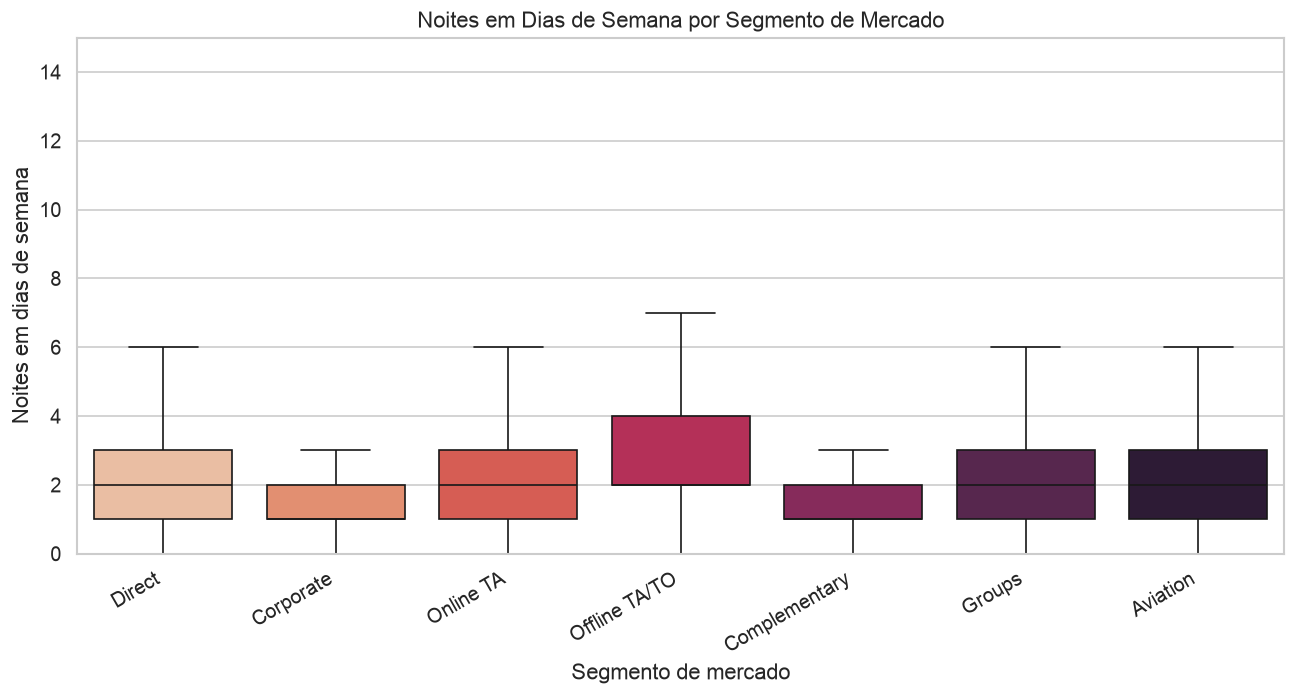

In [ ]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="market_segment", y="stays_in_week_nights", hue="market_segment",
            palette="rocket_r", legend=False, showfliers=False)
plt.title("Noites em Dias de Semana por Segmento de Mercado")
plt.xlabel(ROTULOS["market_segment"])
plt.ylabel(ROTULOS["stays_in_week_nights"])
plt.ylim(0, 15)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `market_segment`?

**✍️ Resposta (análise individual)**

Como já sabemos que `stays_in_week_nights` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste. E lembrem que os dois só dizem "existe pelo menos um grupo diferente" — pra saber *quais* segmentos diferem entre si seria preciso um teste post-hoc.

#### Quantitativa x Qualitativa

In [ ]:
contingencia_deposito = pd.crosstab(df["deposit_type"], df["cancelamento"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_deposito)
p_chi2_txt = "p < 0.001" if p_chi2 < 1e-3 else f"p = {p_chi2:.4g}"

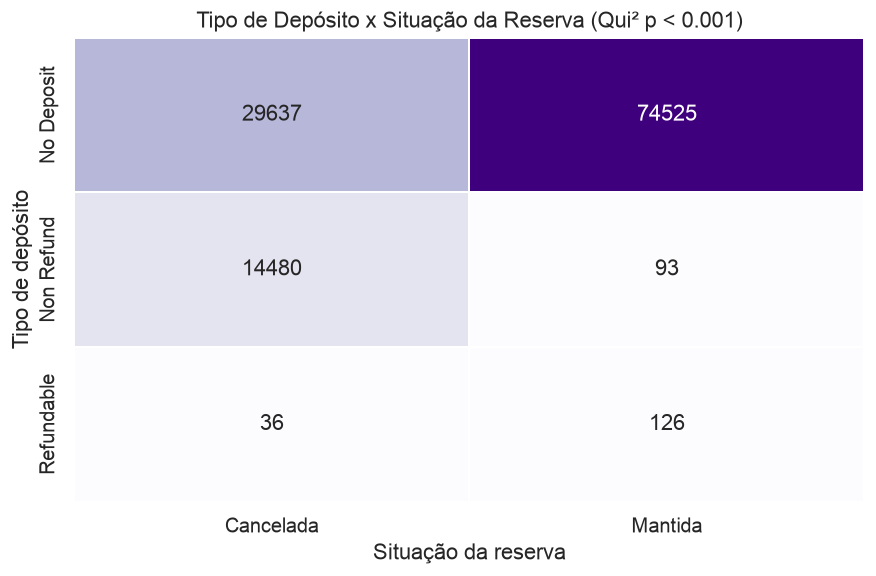

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(contingencia_deposito, annot=True, fmt="d", cmap="Purples", linewidths=1,
            linecolor="white", cbar=False, annot_kws={"fontsize": 13}, ax=ax)
ax.set_title(f"Tipo de Depósito x Situação da Reserva (Qui² {p_chi2_txt})")
ax.set_xlabel("Situação da reserva")
ax.set_ylabel(ROTULOS["deposit_type"])
plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> o p-valor do Qui-Quadrado indica que `deposit_type` e `cancelamento` são independentes, ou há associação estatisticamente significativa entre elas?

**✍️ Resposta (análise individual)**

Olhem a tabela com atenção: reservas do tipo "Non Refund" são canceladas em praticamente 100% dos casos. Isso é contraintuitivo — quem paga adiantado e sem direito a reembolso deveria cancelar *menos*, não mais. A explicação mais provável é como o hotel registra no sistema: reservas não reembolsáveis que o hóspede não honrou ficam marcadas como canceladas em vez de "no-show". É um belo exemplo de por que uma associação forte pede investigação de processo, não celebração.

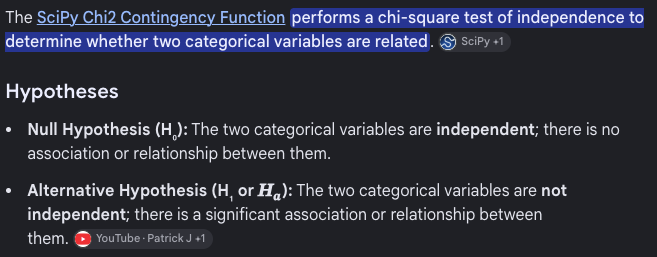

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos? Aqui vamos usar a unidade (City vs. Resort) e a faixa de antecedência da reserva como subgrupos de exemplo. Uma ressalva honesta: nenhum dos dois é um atributo sensível de verdade — o candidato real a atributo protegido nesta base seria `country`, a nacionalidade do hóspede, e é exatamente aí que a análise ficaria delicada, porque um modelo que aprende a desconfiar de reservas de certos países reproduz discriminação com cara de estatística. A técnica é a mesma; o que muda é o peso ético da conclusão.

Desbalanceamento — unidade do hotel:
n_classes                 2.000
razao_desbalanceamento    2.000
entropia_normalizada      0.918
dtype: float64

Desbalanceamento — faixa de antecedência:
n_classes                 4.000
razao_desbalanceamento    2.700
entropia_normalizada      0.936
dtype: float64


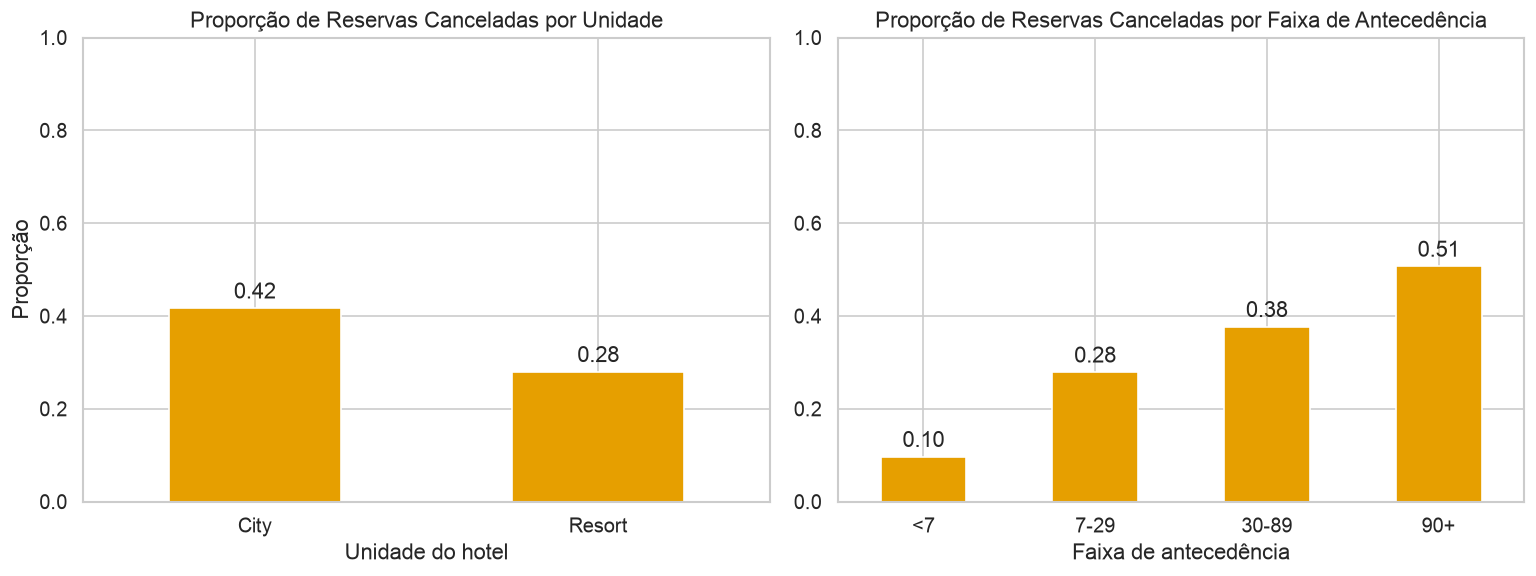

In [ ]:
df["hotel_label"] = df["hotel"].map({"City Hotel": "City", "Resort Hotel": "Resort"})
df["faixa_lead_time"] = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 800],
                             labels=["<7", "7-29", "30-89", "90+"])

print("Desbalanceamento — unidade do hotel:")
print(metrica_desbalanceamento(df["hotel_label"]))
print("\nDesbalanceamento — faixa de antecedência:")
print(metrica_desbalanceamento(df["faixa_lead_time"]))

prop_por_unidade = pd.crosstab(df["hotel_label"], df["cancelamento"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_lead_time"], df["cancelamento"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

prop_por_unidade["Cancelada"].plot(kind="bar", color=COR_DESTAQUE, edgecolor="white", ax=axes[0])
axes[0].set_title("Proporção de Reservas Canceladas por Unidade")
axes[0].set_xlabel(ROTULOS["hotel_label"])
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=3)

prop_por_faixa["Cancelada"].plot(kind="bar", color=COR_DESTAQUE, edgecolor="white", ax=axes[1])
axes[1].set_title("Proporção de Reservas Canceladas por Faixa de Antecedência")
axes[1].set_xlabel(ROTULOS["faixa_lead_time"])
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

> ❓ **Para discutir**
>
> a proporção de cancelamento varia bastante entre as duas unidades ou entre as faixas de antecedência?

**✍️ Resposta (análise individual)**

A diferença por faixa é bem marcante: reservas feitas na última semana quase não são canceladas, enquanto reservas com mais de 90 dias de antecedência são canceladas em cerca de metade dos casos. Isso reflete um comportamento real (planos mudam, e quem reserva cedo tem mais tempo pra mudar de ideia) ou pode ser efeito da política de cancelamento gratuito, que torna a reserva antecipada uma opção sem custo? A pergunta "a distribuição do desfecho é uniforme entre subgrupos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

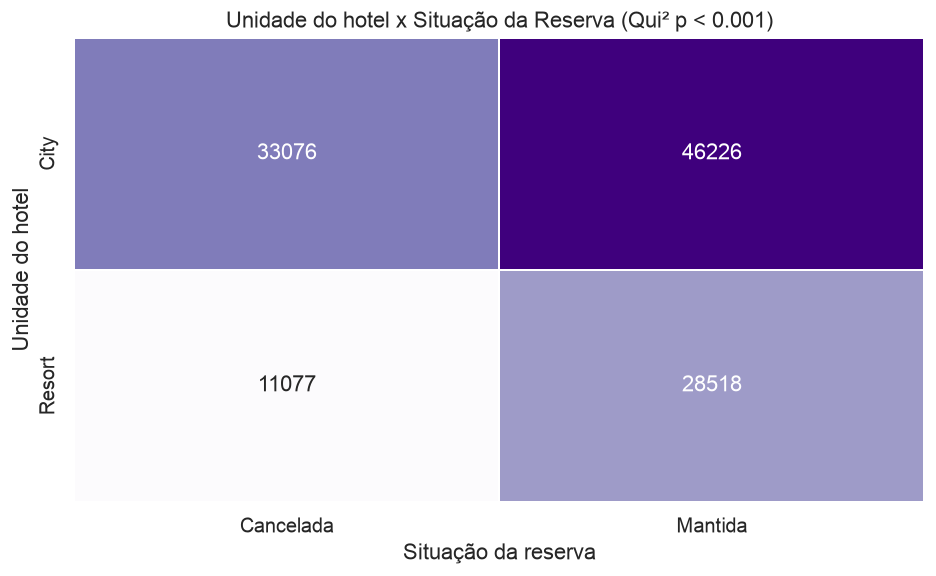

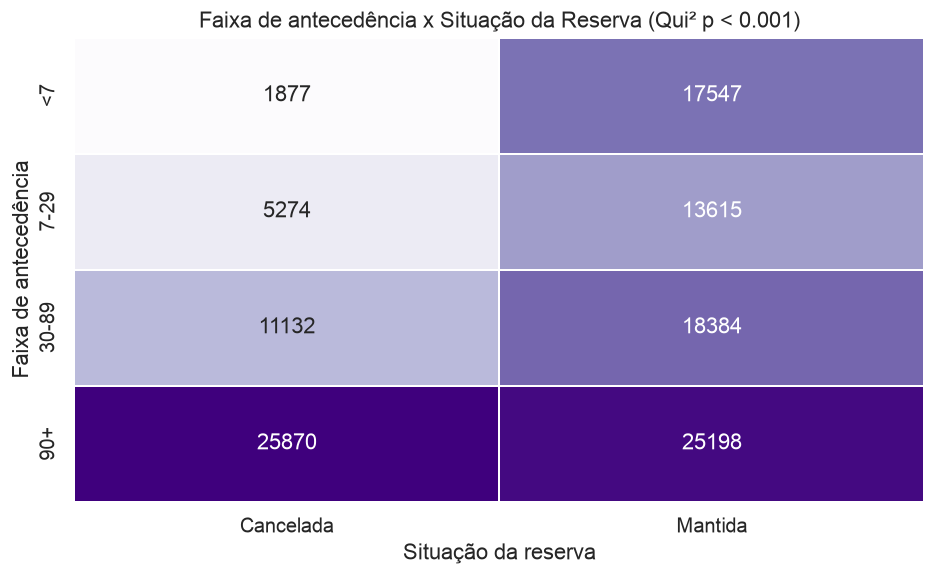

In [ ]:
for atributo in ["hotel_label", "faixa_lead_time"]:
    contingencia = pd.crosstab(df[atributo], df["cancelamento"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)
    p_valor_txt = "p < 0.001" if p_valor < 1e-3 else f"p = {p_valor:.4g}"

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="Purples", linewidths=1,
                linecolor="white", cbar=False, annot_kws={"fontsize": 13}, ax=ax)
    ax.set_title(f"{ROTULOS[atributo]} x Situação da Reserva (Qui² {p_valor_txt})")
    ax.set_xlabel("Situação da reserva")
    ax.set_ylabel(ROTULOS[atributo])
    plt.tight_layout()
    plt.show()

> ❓ **Para discutir**
>
> o Qui-Quadrado confirma associação estatisticamente significativa entre a unidade do hotel / faixa de antecedência e o cancelamento?

**✍️ Resposta (análise individual)**

Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um comportamento real do hóspede (antecedência), pode ser a política comercial de cada unidade, ou pode ser a forma como o sistema registra cada tipo de reserva. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

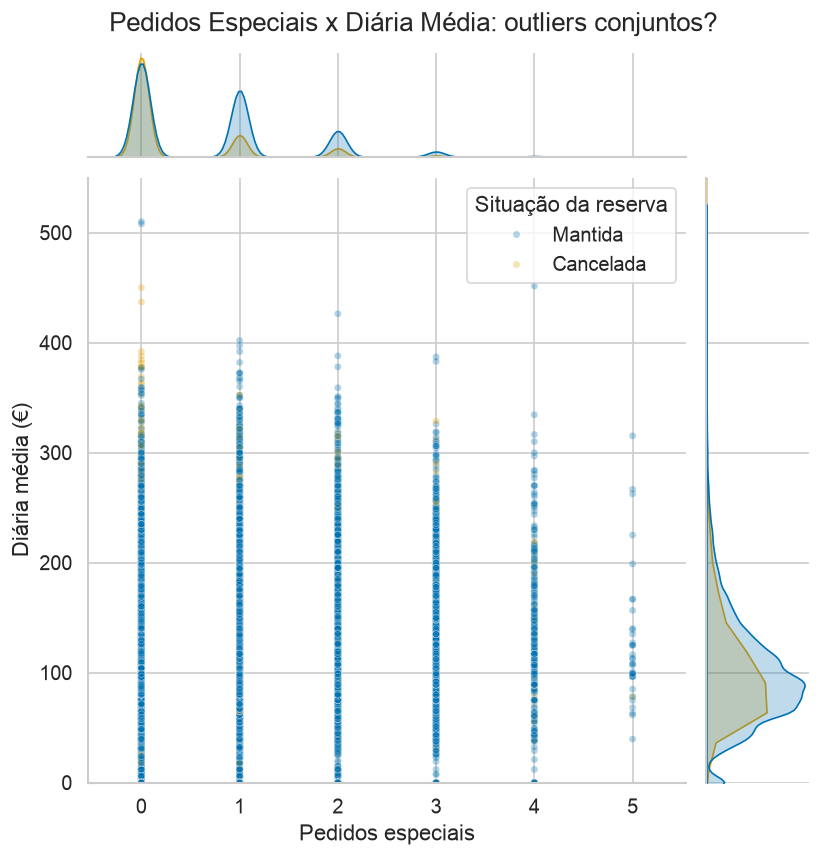

In [ ]:
grafico_conjunto = sns.jointplot(data=df, x="total_of_special_requests", y="adr", hue="cancelamento",
              palette={"Mantida": COR_CONTEXTO, "Cancelada": COR_DESTAQUE}, alpha=0.3, s=18, height=7)
grafico_conjunto.set_axis_labels(ROTULOS["total_of_special_requests"], ROTULOS["adr"])
grafico_conjunto.ax_joint.get_legend().set_title("Situação da reserva")
grafico_conjunto.ax_joint.set_ylim(0, 550)
plt.suptitle("Pedidos Especiais x Diária Média: outliers conjuntos?", y=1.02)
plt.show()

> ❓ **Para discutir**
>
> existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `total_of_special_requests` e `adr`?

**✍️ Resposta (análise individual)**

Uma reserva de diária baixíssima com muitos pedidos especiais, por exemplo, é estranha do ponto de vista do negócio mesmo que nenhum dos dois valores, isolado, chame atenção.

#### Análise Multivariada

##### Matriz de Correlação

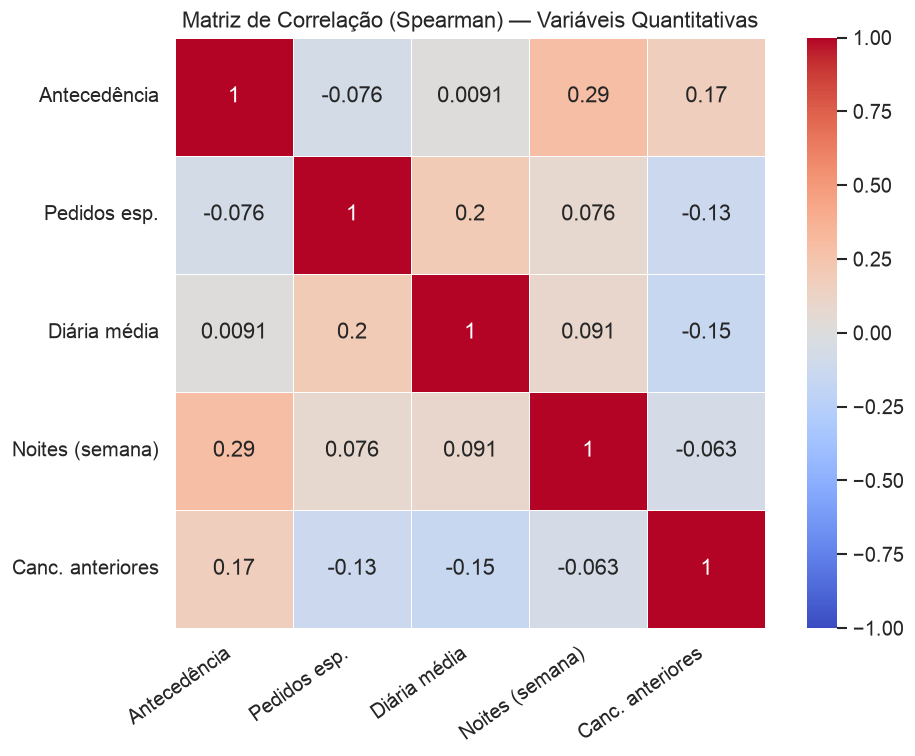

In [ ]:
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(df[VARS_QUANT].corr(method="spearman").rename(index=ROTULOS_CURTOS, columns=ROTULOS_CURTOS),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor="white")
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

> ❓ **Para discutir**
>
> Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

**✍️ Resposta (análise individual)**

Não. Olhando a matriz de Spearman das quantitativas, a correlação mais forte entre variáveis diferentes é `lead_time` × noites de semana, e mesmo assim fica em ≈ 0,30 (moderada pra fraca). Todas as outras estão abaixo disso, a maioria pertinho de zero.

Como nenhum par chega perto de 0,7 (o limiar de correlação "forte"), eu concluo que **não há redundância**: cada variável quantitativa carrega informação própria e nenhuma é praticamente uma cópia da outra. Na prática isso é bom — se eu fosse alimentar um modelo, não precisaria descartar nenhuma delas por multicolinearidade. O correlograma logo abaixo conta a mesma história de forma visual: círculos pequenos e claros fora da diagonal.


##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

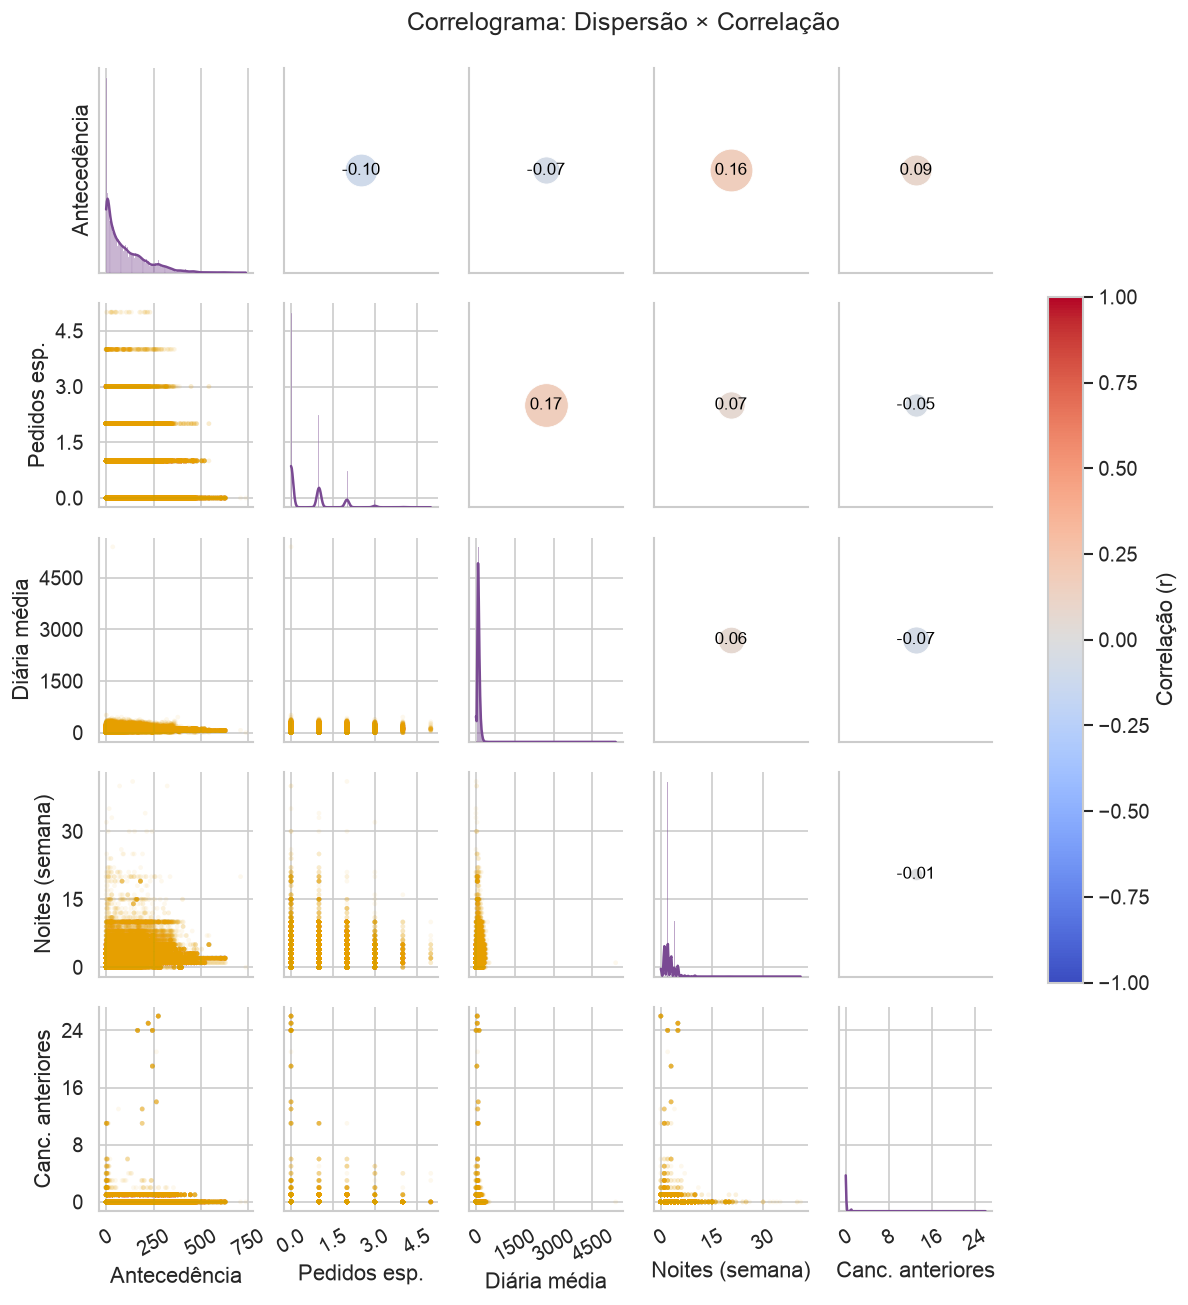

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False, height=2.1)
g.map_lower(sns.scatterplot, color=COR_DESTAQUE, alpha=0.07, s=8, edgecolor="none")
g.map_diag(sns.histplot, color=PALETA_VARS["adr"], kde=True, edgecolor="white")
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

for i, col in enumerate(VARS_QUANT):
    g.axes[-1, i].set_xlabel(ROTULOS_CURTOS[col])
    g.axes[i, 0].set_ylabel(ROTULOS_CURTOS[col])
    g.axes[-1, i].xaxis.set_major_locator(plt.MaxNLocator(4))
    g.axes[-1, i].tick_params(axis="x", labelbottom=True, rotation=30)
    if i > 0:
        g.axes[i, 0].yaxis.set_major_locator(plt.MaxNLocator(4))
        g.axes[i, 0].tick_params(axis="y", labelleft=True)

g.axes[0, 0].tick_params(axis="y", labelleft=False)

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.

## Síntese Final

Fechando o trabalho, reúno aqui as principais conclusões da minha EDA e a declaração de uso de IA, como pedido.


### 1. Principais conclusões

1. **A antecedência da reserva (`lead_time`) é o marcador mais forte de cancelamento.** Reservas canceladas têm mediana de 113 dias de antecedência contra 45 das mantidas, e a taxa de cancelamento sobe de 10% (reservas de última hora, `<7` dias) para 51% (`90+` dias). Esse sinal apareceu de forma consistente no histograma por classe, no boxplot e na visão por faixa de antecedência.

2. **O tipo de depósito esconde um problema de processo, não um insight comercial.** Reservas "Non Refund" são canceladas em praticamente 99% dos casos — o oposto do que a intuição diria de quem paga adiantado. A explicação mais provável é o sistema registrar *no-show* como cancelamento. É o exemplo de que uma associação forte pede investigação do processo, não comemoração.

3. **As variáveis quantitativas são todas assimétricas e não-normais**, e o Shapiro-Wilk rejeita normalidade em todas. Por isso reportei como principais os testes **não-paramétricos** (Mann-Whitney, Kruskal-Wallis e correlação de Spearman). E como a base tem ~119 mil linhas, quase tudo dá p-valor microscópico — então olhei o **tamanho do efeito**, não só a significância.

4. **O tratamento foi conservador e documentado.** Removi a coluna `company` (94% vazia, sem valor analítico), removi menos de 0,5% das linhas por ausência em `country`/`children`, corrigi uma diária negativa (erro de dados impossível) e **mantive** os demais outliers por serem reais e justamente o sinal de interesse. A comparação "antes x depois" confirmou que as distribuições mal se moveram — sinal de que o tratamento não distorceu a base.

5. **Não há redundância entre as quantitativas** (maior correlação ≈ 0,30), então cada uma carrega informação própria; e o alvo tem desbalanceamento apenas leve (≈ 37% canceladas), confortável tanto para a análise bivariada quanto para um eventual modelo mais à frente.


### 2. Declaração de Uso de IA

- **Ferramenta utilizada:** assistente de IA (Claude), além do ambiente do Google Colab para executar o notebook.
- **Para o que foi aplicada:** apoio na organização do notebook, revisão do código de EDA, discussão sobre qual método estatístico usar em cada caso (paramétrico x não-paramétrico), redação e revisão das discussões, e conferência da legibilidade dos gráficos.
- **O que aceitei:** a recomendação de priorizar testes **não-paramétricos** depois que o Shapiro-Wilk rejeitou normalidade; a decisão de **remover `company`** e de **corrigir a diária negativa** como erro de dados; e os ajustes de rótulos e cores que deixaram os gráficos mais legíveis.
- **O que modifiquei:** reescrevi todas as discussões com as minhas próprias palavras e conclusões, ajustei o texto para a primeira pessoa e amarrei cada resultado ao contexto do negócio hoteleiro.
- **O que rejeitei e por quê:** rejeitei remover/transformar automaticamente os outliers "estatísticos" (diárias altas, estadias longas), porque são reservas reais e representam exatamente o comportamento que eu quero estudar; e rejeitei tirar conclusão só pelo p-valor, por causa do tamanho da amostra, preferindo sustentar as conclusões no tamanho de efeito e no conhecimento de domínio.
